# 06 · MedDRA versions: FDA's terms against today's MedDRA

For anyone checking how Open Altio reads the MedDRA terms in FAERS. FDA codes every reaction and every indication to MedDRA, the dictionary of medical terms that regulators share, and publishes the term as text. MedDRA puts out two versions a year (x.0 in March, x.1 in September), and from one to the next a preferred term (PT) can be demoted to a lower level term (LLT) under another PT, an LLT can be made non-current, and a term can be renamed. So an older report can name a term that is no longer a PT, and a search on today's term misses it. This notebook measures that gap on a release, checks the three steps that answer it (`rules/meddra-terms.md`, `rules/meddra-version.md`, `rules/legacy-term-spelling.md`), and ends with the choices made, each with its numbers.

**MedDRA in brief.** A lower level term is a word a reporter might use; each belongs to exactly one PT, and every PT is also an LLT of itself. MedDRA never deletes a term: a PT it demotes stays as an LLT pointing to its current PT, and a renamed term keeps its code, with its old name in MedDRA's history file (`meddra_history_english.asc`, in the same download). FAERS's reaction field holds only PTs.

**Grain.** A *reaction row* is one row of `reac_latest_T`: the reactions of the latest version of each case, after FDA's deleted-case lists. A *text* is a distinct value of FDA's column; a *term* is a text compared the way the explorer compares reactions (lower case, runs of spaces made one). A *case* is a row of `case_latest_T`, probable duplicates included, unless a chart says it counts the default case set (one case per duplicate group). "Quarter" is the quarter of the case's latest version: the file its rows were published in.

**What it reads.** A release folder built by the command line (`open-altio demo` or `open-altio build`): `RELEASE` in the first code cell, or `OPEN_ALTIO_RELEASE`. And MedDRA's English ASCII release, unzipped (the folder that holds `MedAscii/`), from `OPEN_ALTIO_MEDDRA`: the folder `open-altio serve --meddra` takes. MedDRA's files are read by the release build's own code (`open_altio.faers.meddra`, `open_altio.faers.spelling`), so what is measured is what a release carries. Every headline number is checked by a second count written apart from that code, with this notebook's own reading of MedDRA's files.

**MedDRA is licensed.** Its terms, codes and the mapping between them reach only people who hold MedDRA. This notebook writes nothing of MedDRA's into the release; its working tables, MedDRA's among them, sit in a scratch database beside the executed copy (`notebooks/out/`, which git ignores) and are removed at the end of the run. The executed copy shows terms as examples; the copy in git carries the outputs of a run on the release named below, with the outputs that show MedDRA beyond the Preferred Term names (a lower level term mapped to its PT, SMQs) cleared. Run it with your own MedDRA files to see them.

Sections: 1 where FAERS keeps MedDRA terms; 2 which MedDRA version each quarter was coded in; 3 reaction terms that are not current PTs; 4 capital letters and MedDRA's spelling; 5 how old terms map to current PTs, and what mapping cannot do; 6 renamed terms and the history file; 7 indications and the reaction that came back on re-exposure; 8 the build's mapping checked; 9 what counting under current PTs changes for statistics; the methods-page cards; the choices made. Each section ends with one item per chart: what it **shows**, its **point**, and **so what** for a choice or the build.

In [1]:
import os
import textwrap
from datetime import date
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from open_altio.faers import meddra, spelling
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import (
    ERA,
    SERIES,
    label_bars,
    mark_quarters,
    out_dir,
    plot_card,
    quarter_ticks,
    setup,
    title,
    write_cards,
)
from open_altio.faers.insights.source import release_folder
from open_altio.faers.reader import register_release
from open_altio.faers.schema import RAW_COLUMNS

setup(colwidth=70)


def say(text):
    """Prose that quotes this run's numbers."""
    display(Markdown(textwrap.dedent(text).strip()))


def need(name):
    value = os.environ.get(name)
    assert value, f"set {name} (see the first cell)"
    return Path(value).expanduser()


# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
SOURCE = release_folder(RELEASE)
MEDDRA = meddra.source(need("OPEN_ALTIO_MEDDRA"))  # MedDRA's English ASCII release, unzipped
VERSION = MEDDRA.version
WORK = out_dir() / "06_meddra_versions"
(WORK / "tmp").mkdir(parents=True, exist_ok=True)
DB = (
    WORK / f"{SOURCE.name}.duckdb"
)  # working tables, MedDRA's among them: removed at the end of the run
if DB.exists():
    DB.unlink()
con = duckdb.connect(str(DB))
con.execute(
    f"SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    f"SET preserve_insertion_order = false; SET temp_directory = '{WORK / 'tmp'}'"
)  # other jobs share the machine
register_release(con, SOURCE, temporary=True)


def q(sql):
    return con.execute(sql).fetchdf()


def one(sql):
    return con.execute(sql).fetchone()


# The build's own step: MedDRA's files, and FDA's terms in pt, drug_rec_act and indi_pt read to
# them (reac_meddra_T, drug_rec_act_meddra_T, indi_meddra_T), with the report the build logs.
REPORT = meddra.map_licensed(con, MEDDRA)
for line in meddra.report_lines(VERSION, REPORT):
    print(line)
key = meddra.key_sql


# This notebook's own reading of MedDRA's files, for the second counts: its own parser, its own
# key (POSIX space classes rather than the build's \s), PT status from every A and D record.
def rd(name, *fields):
    """MedDRA's file `name`, its first fields named in order (an empty name passes one by)."""
    names = ", ".join(f"'{f or f'skip{i}'}'" for i, f in enumerate(fields))
    return (
        f"read_csv('{MEDDRA.folder / name}', delim = '$', header = false, all_varchar = true, quote = '', "
        f"escape = '', encoding = 'latin-1', names = [{names}])"
    )


con.execute(
    "CREATE MACRO own_key(x) AS nullif(trim(regexp_replace(lower(x), '[[:space:]]+', ' ', 'g')), '')"
)
con.execute("CREATE MACRO vnum(v) AS split_part(v, '.', 1)::INT * 10 + split_part(v, '.', 2)::INT")
con.execute(
    f"CREATE TABLE own_llt AS SELECT code, name, pt, cur FROM {rd('llt.asc', 'code', 'name', 'pt', *[''] * 6, 'cur')}"
)
con.execute(f"CREATE TABLE own_pt AS SELECT code, name FROM {rd('pt.asc', 'code', 'name')}")
con.execute(f"""CREATE TABLE own_hist AS SELECT *, vnum(ver) AS v FROM (
  SELECT code, name, ver, lvl, act FROM {rd("meddra_history_english.asc", "code", "name", "ver", "lvl", "", "act")})""")
con.execute("""CREATE TABLE own_name AS            -- every name, current or former, with its code and PT
  WITH now AS (SELECT own_key(name) AS k, code, pt, cur, code = pt AS is_pt FROM own_llt)
  SELECT k, code, pt, cur, is_pt, FALSE AS former FROM now
  UNION ALL
  SELECT DISTINCT own_key(h.name), h.code, l.pt, NULL, NULL, TRUE FROM own_hist h JOIN own_llt l ON l.code = h.code
  WHERE h.lvl IN ('PT', 'LLT') AND own_key(h.name) NOT IN (SELECT k FROM now)""")
assert (
    one("SELECT count(*) - count(DISTINCT k) FROM own_name")[0] == 0
)  # one name, one term: matching is unambiguous

# Reaction rows per era, quarter and text, and each text's class through the build's mapping:
# written exactly as a current PT; a current PT in other capitals or spacing; a current or a
# non-current LLT; a former name; nothing.
CLASSES = ["pt_exact", "pt_case", "llt_current", "llt_noncurrent", "former_name", "none"]
LABEL = {
    "pt_exact": "written exactly as a current PT",
    "pt_case": "a current PT in other capitals",
    "llt_current": "a current LLT, not a PT",
    "llt_noncurrent": "a non-current LLT",
    "former_name": "a former MedDRA name",
    "none": "no MedDRA name",
}
COLOR = {
    "pt_exact": SERIES[7],
    "pt_case": SERIES[6],
    "llt_current": SERIES[0],
    "llt_noncurrent": SERIES[3],
    "former_name": SERIES[4],
    "none": SERIES[1],
}
OLD = (
    "llt_current",
    "llt_noncurrent",
    "former_name",
    "none",
)  # not a current PT, whatever the capitals
CLASS_SQL = """CASE WHEN p.pt_name IS NOT NULL THEN 'pt_exact' WHEN m.pt_current_T THEN 'pt_case'
  WHEN m.matched_as_T = 'llt' AND m.llt_current_T THEN 'llt_current' WHEN m.matched_as_T = 'llt' THEN 'llt_noncurrent'
  WHEN m.matched_as_T = 'former_name' THEN 'former_name' ELSE 'none' END"""
con.execute(
    "CREATE TABLE rq_T AS SELECT era_T, quarter_T, pt AS text, count(*) AS n_rows FROM reac_latest_T "
    "WHERE pt IS NOT NULL GROUP BY ALL"
)
con.execute(f"""CREATE TABLE rtext_T AS
SELECT d.text, m.reac_term_T AS key_T, {CLASS_SQL} AS class_T, m.pt_code_T, m.llt_code_T
FROM (SELECT DISTINCT text FROM rq_T) d LEFT JOIN reac_meddra_T m ON m.reac_term_T = {key("pt", "d.text")}
LEFT JOIN meddra_pt p ON p.pt_name = d.text""")
con.execute(
    "CREATE TABLE rx_T AS SELECT r.*, t.key_T, t.class_T, t.pt_code_T, t.llt_code_T FROM rq_T r JOIN rtext_T t USING (text)"
)
# One row per case: whether it carries an old term, whether a search on a current PT misses it (an
# old term whose current PT FDA did not also write on it), whether two of its terms meet in one PT.
con.execute("""CREATE TABLE rcase_T AS
WITH pairs AS (SELECT r.era_T, r.primaryid, r.quarter_T, t.pt_code_T,
                      bool_or(t.class_T IN ('pt_exact', 'pt_case')) AS direct_T,
                      bool_or(t.class_T NOT IN ('pt_exact', 'pt_case')) AS older_T, count(DISTINCT t.key_T) AS n_keys_T
               FROM reac_latest_T r JOIN rtext_T t ON t.text = r.pt GROUP BY ALL)
SELECT c.case_key_T, c.era_T, c.dup_kept_T, bool_or(older_T) AS carries_T, bool_or(older_T AND NOT direct_T) AS missed_T,
       sum(n_keys_T) > count(*) AS merged_T
FROM pairs p JOIN case_latest_T c USING (era_T, primaryid, quarter_T) GROUP BY ALL""")
assert one("SELECT count(*) - count(DISTINCT case_key_T) FROM case_latest_T")[0] == 0
quarters = q("SELECT quarter_T FROM quarters_T ORDER BY qnum_T").quarter_T.tolist()
TOTAL = one("SELECT sum(n_rows), count(*) FROM rq_T")
CASES = one("SELECT count(*) FROM rcase_T")[0]
print(
    f"release {SOURCE.name} | MedDRA {VERSION} {MEDDRA.language} | reaction rows {TOTAL[0]:,.0f} on {CASES:,} cases"
)

MedDRA 29.1, pt: 25,231 distinct texts, 47 placed through the history file, 0 matching nothing (0 rows)
MedDRA 29.1, drug_rec_act: 5,091 distinct texts, 3 placed through the history file, 0 matching nothing (0 rows)
MedDRA 29.1, indi_pt: 21,289 distinct texts, 24 placed through the history file, 74 matching nothing (105 rows)
MedDRA 29.1: quarters fitting no single version: 2017Q1 (nearest 19.1, 2 rows off)


release 2026Q2-final-v3 | MedDRA 29.1 English | reaction rows 61,393,379 on 20,588,478 cases


## 1 · Where FAERS keeps MedDRA terms

Each FDA column of the seven case tables, on the case set, is checked for how many of its filled rows are a MedDRA name (any current or former name, compared as terms). A column that holds MedDRA terms is a name on every row; any other column matches only where a short code happens to spell one.

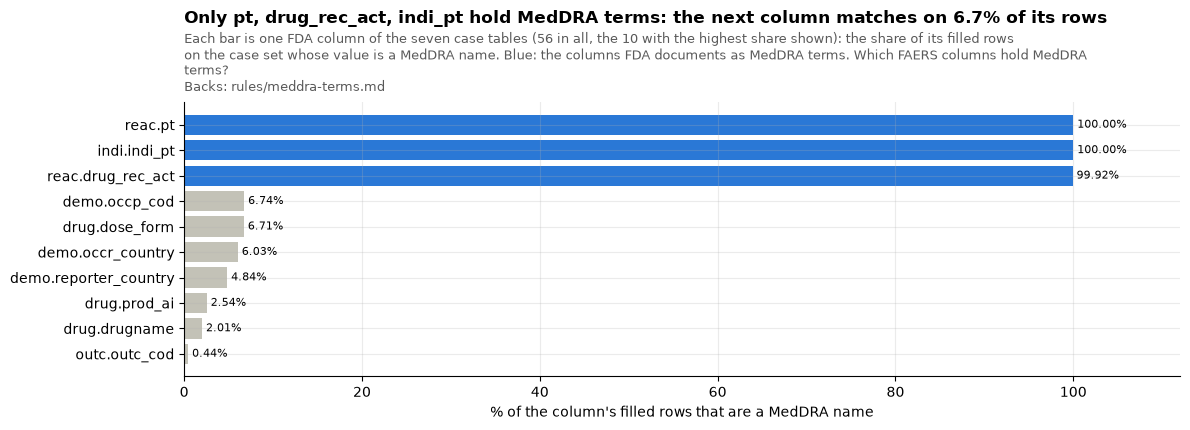

,table,column,filled,names,share
0,reac,pt,61393379,61393379,100.000000
1,indi,indi_pt,49127336,49127231,99.999786
2,reac,drug_rec_act,95783,95706,99.919610
3,demo,occp_cod,19299047,1301523,6.743975
4,drug,dose_form,29700408,1993502,6.712036
5,demo,occr_country,16701202,1007348,6.031590


In [2]:
found = []
for table, columns in RAW_COLUMNS.items():
    if table == "deleted":
        continue
    columns = [c for c in columns if c not in ("primaryid", "caseid")]
    parts = ", ".join(
        f"count({c}), count(*) FILTER (WHERE own_key({c}) IN (SELECT k FROM own_name))"
        for c in columns
    )
    got = one(f"SELECT {parts} FROM {table}_latest_T")
    found += [(table, c, got[2 * i], got[2 * i + 1]) for i, c in enumerate(columns)]
fields = pd.DataFrame(found, columns=["table", "column", "filled", "names"])
fields["share"] = 100 * fields.names / fields.filled.where(fields.filled > 0)
fields = fields.sort_values("share", ascending=False).reset_index(drop=True)
TERM_COLUMNS = ["pt", "drug_rec_act", "indi_pt"]
top = fields.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 4.4))
bars = ax.barh(
    top.table + "." + top.column,
    top.share,
    color=[SERIES[0] if c in TERM_COLUMNS else SERIES[7] for c in top.column],
)
label_bars(ax, bars, "{:.2f}%", horizontal=True)
ax.set_xlim(0, 112)
ax.set_xlabel("% of the column's filled rows that are a MedDRA name")
title(
    ax,
    f"Only {', '.join(TERM_COLUMNS)} hold MedDRA terms: the next column matches on {fields.share.iloc[3]:.1f}% of its rows",
    f"Each bar is one FDA column of the seven case tables ({len(fields)} in all, the 10 with the highest share shown): "
    "the share of its filled rows on the case set whose value is a MedDRA name. Blue: the columns FDA documents as MedDRA terms.",
    "Which FAERS columns hold MedDRA terms?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
assert list(fields.column[:3]) == ["pt", "indi_pt", "drug_rec_act"] and fields.share.iloc[3] < 10
fields.head(6)

In [3]:
say(f"""
**What section 1 shows**, one item per chart:

- **Which columns hold MedDRA terms.** *Shows:* of the {len(fields)} FDA columns, three are a MedDRA name on nearly every filled row: `pt` ({fields.share[fields.column == "pt"].iloc[0]:.2f}% of {fields.filled[fields.column == "pt"].iloc[0]:,} rows), `indi_pt` ({fields.share[fields.column == "indi_pt"].iloc[0]:.3f}%) and `drug_rec_act` ({fields.share[fields.column == "drug_rec_act"].iloc[0]:.2f}% of {fields.filled[fields.column == "drug_rec_act"].iloc[0]:,} rows); the next, `{fields.column.iloc[3]}`, reaches {fields.share.iloc[3]:.1f}%, where its short codes spell a term. *Point:* FAERS keeps MedDRA terms in three columns and nowhere else. *So what:* the mapping covers exactly `pt`, `drug_rec_act` and `indi_pt`, with one piece of code (`rules/meddra-terms.md`).
""")

**What section 1 shows**, one item per chart:

- **Which columns hold MedDRA terms.** *Shows:* of the 56 FDA columns, three are a MedDRA name on nearly every filled row: `pt` (100.00% of 61,393,379 rows), `indi_pt` (100.000%) and `drug_rec_act` (99.92% of 95,783 rows); the next, `occp_cod`, reaches 6.7%, where its short codes spell a term. *Point:* FAERS keeps MedDRA terms in three columns and nowhere else. *So what:* the mapping covers exactly `pt`, `drug_rec_act` and `indi_pt`, with one piece of code (`rules/meddra-terms.md`).

## 2 · Which MedDRA version each quarter was coded in

FAERS does not say which MedDRA version a report was coded in, but the terms do. A term's code is a PT in some versions and not in others (the history file records every time a code was made a PT and every time it was demoted). A quarter **fits** a version when every one of its reaction rows names a term that was a PT in that version. The test is two-sided: a version too old misses the quarter's newest terms, and a version too new has already demoted some of its terms. The quarter's version is then set beside MedDRA's calendar: the newest version MedDRA had published by the end of the quarter.

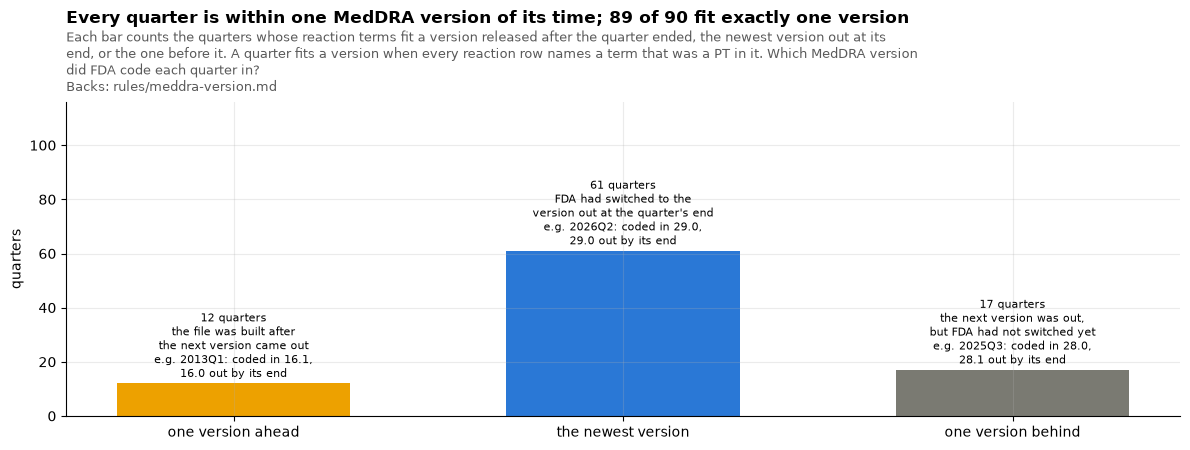

89 of 90 quarters fit exactly one version; fitting none: 2017Q1 (19.1 but for 2 rows); the build reports the same. Ahead: 2004Q1, 2004Q2, 2005Q4, 2008Q4, 2009Q4, 2012Q4, 2013Q1, 2013Q2, 2013Q3, 2013Q4, 2014Q2, 2014Q4.


,coded in,newest out by its end,versions from its time
2013q1,16.1,16.0,-1
2017q1,19.1,20.0,1
2025q3,28.0,28.1,1
2026q2,29.0,29.0,0


In [4]:
# PT status by version, from the history file as this notebook reads it
versions = q("SELECT DISTINCT ver, v FROM own_hist ORDER BY v").ver.tolist()
vi = {ver: i for i, ver in enumerate(versions)}
events = q(
    "SELECT code, ver, act FROM own_hist WHERE lvl = 'PT' AND act IN ('A', 'D') ORDER BY code, v, act"
)
codes = sorted(set(events.code))
ci = {code: i for i, code in enumerate(codes)}
is_pt = np.zeros((len(codes), len(versions)), dtype=bool)
for code, g in events.groupby("code", sort=False):
    status = np.full(len(versions), -1)
    for ver, act in zip(g.ver, g.act, strict=True):
        status[vi[ver] :] = 1 if act == "A" else 0
    is_pt[ci[code]] = status == 1
# reaction rows by quarter and the term's code, read through this notebook's own names
rows_by_code = q(
    "SELECT r.quarter_T, n.code, sum(r.n_rows) AS n FROM rq_T r JOIN own_name n ON n.k = own_key(r.text) GROUP BY ALL"
)
assert rows_by_code.n.sum() == TOTAL[0]  # every reaction row is a MedDRA name, current or former
grid = rows_by_code.pivot_table(
    index="quarter_T", columns="code", values="n", aggfunc="sum", fill_value=0
)
known = np.zeros((grid.shape[1], len(versions)), dtype=bool)
where = [ci.get(c) for c in grid.columns]
known[[i for i, w in enumerate(where) if w is not None]] = is_pt[
    [w for w in where if w is not None]
]
fit = pd.DataFrame(
    grid.values @ (~known).astype(np.int64), index=grid.index, columns=versions
)  # rows off, per version
fits = fit.apply(lambda r: [ver for ver in versions if r[ver] == 0], axis=1)
coded = pd.Series(
    {qq: fits[qq][0] if len(fits[qq]) == 1 else fit.loc[qq].idxmin() for qq in fit.index}
)


def quarter_end(qq):
    y, n = int(qq[:4]), int(qq[-1])
    return date(y + (n == 4), 1 if n == 4 else 3 * n + 1, 1)


calendar = [
    ver for ver in versions if int(ver.split(".")[0]) >= 6 and int(ver.split(".")[1]) < 2
]  # x.0 and x.1
newest = pd.Series(
    {
        qq: max((ver for ver in calendar if meddra.release_date(ver) < quarter_end(qq)), key=vi.get)
        for qq in fit.index
    }
)
steps = pd.Series({qq: vi[newest[qq]] - vi[coded[qq]] for qq in fit.index})
NAMES = {-1: "one version ahead", 0: "the newest version", 1: "one version behind"}
assert set(steps) <= set(NAMES)  # no quarter is more than one version from its time, either way
EXAMPLE = {-1: "2013q1", 0: quarters[-1], 1: "2025q3"}
example = {
    s: (EXAMPLE[s] if steps.get(EXAMPLE[s]) == s else steps[steps == s].index[-1])
    for s in NAMES
    if (steps == s).any()
}
REASON = {
    -1: "the file was built after\nthe next version came out",
    0: "FDA had switched to the\nversion out at the quarter's end",
    1: "the next version was out,\nbut FDA had not switched yet",
}
lag = steps.value_counts().reindex(list(NAMES), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.6))
bars = ax.bar(
    [NAMES[s] for s in NAMES], lag.values, color=[SERIES[3], SERIES[0], SERIES[6]], width=0.6
)
for b, s in zip(bars, NAMES, strict=True):
    if s in example:
        qq = example[s]
        ax.text(
            b.get_x() + b.get_width() / 2,
            b.get_height() + 1,
            f"{int(b.get_height())} quarters\n{REASON[s]}\ne.g. {qq.upper()}: coded in {coded[qq]},\n{newest[qq]} out by its end",
            ha="center",
            va="bottom",
            fontsize=8,
        )
ax.set_ylim(0, lag.max() * 1.9)
ax.set_ylabel("quarters")
off_one = fits[fits.str.len() != 1]
title(
    ax,
    f"Every quarter is within one MedDRA version of its time; {(fits.str.len() == 1).sum()} of {len(fits)} fit exactly one version",
    "Each bar counts the quarters whose reaction terms fit a version released after the quarter ended, the newest version out "
    "at its end, or the one before it. A quarter fits a version when every reaction row names a term that was a PT in it.",
    "Which MedDRA version did FDA code each quarter in?",
    "Backs: rules/meddra-version.md",
)
plt.tight_layout()
plt.show()
build_off = {
    x["quarter"]: (x["nearest"], x["rows_off"]) for x in REPORT["quarters_fitting_no_version"]
}
mine_off = {qq: (fit.loc[qq].idxmin(), int(fit.loc[qq].min())) for qq in off_one.index}
assert mine_off == build_off, (mine_off, build_off)  # the build's report, counted apart
print(
    f"{(fits.str.len() == 1).sum()} of {len(fits)} quarters fit exactly one version; fitting none: "
    + ", ".join(f"{qq.upper()} ({v} but for {n} rows)" for qq, (v, n) in mine_off.items())
    + f"; the build reports the same. Ahead: {', '.join(x.upper() for x in steps[steps < 0].index)}."
)
pd.DataFrame(
    {"coded in": coded, "newest out by its end": newest, "versions from its time": steps}
).loc[sorted(set(example.values()) | set(mine_off))]

### FDA recodes its database, but a quarterly file is a snapshot

FDA keeps its database in the current MedDRA version, but each quarterly file is extracted once, in the version current when FDA built it, and an old file is never reissued. The evidence is in the reports FDA published in more than one quarterly file (the same report version, `era_T` and `primaryid`, in two files): when the later file came out after a new MedDRA version, its terms have moved to that version.

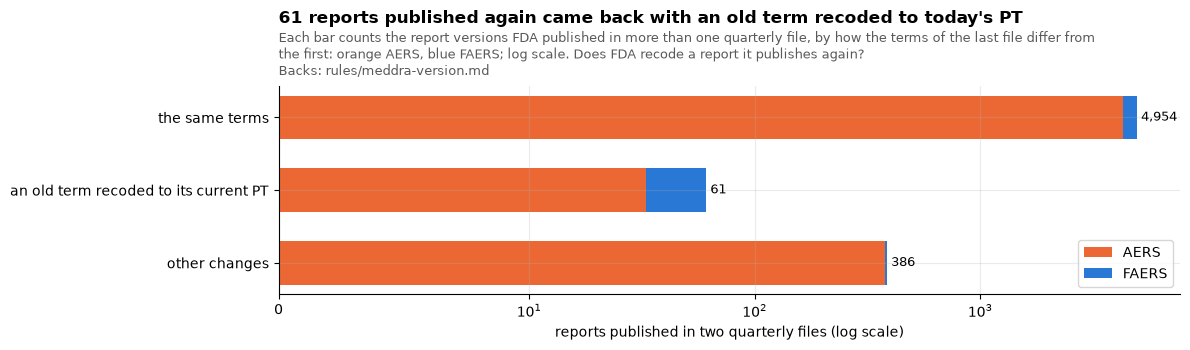

For example, 10 FAERS reports first published under 'Renal failure acute' in 2013Q1 to 2014Q3 come back in 2020Q3 as 'Acute kidney injury'.


era_T,faers,legacy,all
change_T,,,
the same terms,671,4283,4954
an old term recoded to its current PT,28,33,61
other changes,8,378,386


In [5]:
con.execute(f"""CREATE TABLE rep_T AS
WITH r AS (SELECT era_T, primaryid, quarter_T, pt FROM reac WHERE pt IS NOT NULL),
many AS (SELECT era_T, primaryid, min(quarter_T) AS first_T, max(quarter_T) AS last_T
         FROM (SELECT DISTINCT era_T, primaryid, quarter_T FROM r) GROUP BY ALL HAVING count(*) > 1)
SELECT m.*, r.quarter_T = m.first_T AS first_file_T, r.pt, x.pt_code_T, x.pt_current_T
FROM r JOIN many m USING (era_T, primaryid) JOIN reac_meddra_T x ON x.reac_term_T = {key("pt", "r.pt")}
WHERE r.quarter_T IN (m.first_T, m.last_T)""")
# a report is recoded when a term of its first file that is no longer a PT comes back in its last file as its current PT
RECODED = """SELECT o.era_T, o.primaryid, o.first_T, o.last_T, o.pt AS old_T, n.pt AS new_T FROM rep_T o JOIN rep_T n USING (era_T, primaryid)
  WHERE o.first_file_T AND NOT n.first_file_T AND NOT o.pt_current_T AND n.pt_current_T AND o.pt_code_T = n.pt_code_T"""
rep = q(f"""
WITH a AS (SELECT era_T, primaryid, list_sort(list_distinct(list(lower(pt)) FILTER (WHERE first_file_T))) AS t1,
                  list_sort(list_distinct(list(lower(pt)) FILTER (WHERE NOT first_file_T))) AS t2 FROM rep_T GROUP BY ALL)
SELECT a.era_T, CASE WHEN t1 = t2 THEN 'the same terms'
                     WHEN (a.era_T, a.primaryid) IN (SELECT (era_T, primaryid) FROM ({RECODED})) THEN 'an old term recoded to its current PT'
                     ELSE 'other changes' END AS change_T, count(*) AS reports
FROM a GROUP BY ALL""").pivot_table(
    index="change_T", columns="era_T", values="reports", aggfunc="sum", fill_value=0
)
rep = rep.reindex(["the same terms", "an old term recoded to its current PT", "other changes"])
pair = q(f"""SELECT old_T, new_T, count(*) AS reports, min(first_T) AS first_T, max(first_T) AS first_last_T, max(last_T) AS last_T
            FROM ({RECODED}) WHERE era_T = 'faers' GROUP BY 1, 2 ORDER BY reports DESC, first_T LIMIT 1""").iloc[
    0
]
fig, ax = plt.subplots(figsize=(12, 3.6))
left = np.zeros(len(rep))
for era in ["legacy", "faers"]:
    ax.barh(
        rep.index[::-1],
        rep[era][::-1],
        left=left[::-1],
        color=ERA[era],
        label={"legacy": "AERS", "faers": "FAERS"}[era],
        height=0.6,
    )
    left += rep[era].values
for i, v in enumerate(rep.sum(axis=1)[::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlabel("reports published in two quarterly files (log scale)")
ax.legend(loc="lower right")
title(
    ax,
    f"{rep.loc['an old term recoded to its current PT'].sum()} reports published again came back with an old term recoded to today's PT",
    "Each bar counts the report versions FDA published in more than one quarterly file, by how the terms of the last file differ "
    "from the first: orange AERS, blue FAERS; log scale.",
    "Does FDA recode a report it publishes again?",
    "Backs: rules/meddra-version.md",
)
plt.tight_layout()
plt.show()
# second count: report versions in more than one file, straight from FDA's rows
twice = one(
    "SELECT count(*) FROM (SELECT era_T, primaryid FROM reac WHERE pt IS NOT NULL GROUP BY ALL HAVING count(DISTINCT quarter_T) > 1)"
)[0]
assert twice == rep.values.sum()
print(
    f"For example, {pair.reports} FAERS reports first published under {pair.old_T!r} in {pair.first_T.upper()} to "
    f"{pair.first_last_T.upper()} come back in {pair.last_T.upper()} as {pair.new_T!r}."
)
rep.assign(all=rep.sum(axis=1))

In [6]:
behind = example.get(1)
say(f"""
**What section 2 shows**, one item per chart:

- **The version each quarter fits.** *Shows:* {(fits.str.len() == 1).sum()} of {len(fits)} quarters fit exactly one MedDRA version, with every reaction row a PT of it; {", ".join(f"{qq.upper()} fits none: {v} fits all but {n} rows" for qq, (v, n) in mine_off.items())}. By MedDRA's calendar, {lag[0]} quarters are on the newest version out at the quarter's end ({example[0].upper()} is on {coded[example[0]]}), {lag[1]} one behind ({behind.upper()}: {newest[behind]} was out, but FDA had not switched from {coded[behind]}), and {lag[-1]} one ahead ({example[-1].upper()}: coded in {coded[example[-1]]}, a version MedDRA published after the quarter ended, because FDA built the file later). None is further off. *Point:* each quarterly file is coded in the MedDRA version current when FDA built it, pinned from both sides. *So what:* older quarters hold older terms because of their age, so reading them to today's terms is mechanical; and a MedDRA file older than the newest quarter's version would leave its newest terms unmatched, so the build refuses one (`rules/meddra-version.md`).
- **Reports published twice.** *Shows:* {rep.values.sum():,} report versions sit in two quarterly files; {rep.loc["the same terms"].sum():,} come back with the same terms, {rep.loc["an old term recoded to its current PT"].sum()} with an old term recoded to its current PT (for example, a report first published in {pair.first_T.upper()} to {pair.first_last_T.upper()} under one term comes back in {pair.last_T.upper()} under its current PT, {pair.reports} times), {rep.loc["other changes"].sum():,} with other changes. *Point:* FDA recodes its own database to each new MedDRA version, but a published file is a snapshot and is never reissued. *So what:* only a reading of FDA's text to today's MedDRA brings old files up to date, and it must be redone for each new MedDRA version: each release takes the newest version out when it is built, and uses that one version throughout (`rules/meddra-version.md`).
""")

**What section 2 shows**, one item per chart:

- **The version each quarter fits.** *Shows:* 89 of 90 quarters fit exactly one MedDRA version, with every reaction row a PT of it; 2017Q1 fits none: 19.1 fits all but 2 rows. By MedDRA's calendar, 61 quarters are on the newest version out at the quarter's end (2026Q2 is on 29.0), 17 one behind (2025Q3: 28.1 was out, but FDA had not switched from 28.0), and 12 one ahead (2013Q1: coded in 16.1, a version MedDRA published after the quarter ended, because FDA built the file later). None is further off. *Point:* each quarterly file is coded in the MedDRA version current when FDA built it, pinned from both sides. *So what:* older quarters hold older terms because of their age, so reading them to today's terms is mechanical; and a MedDRA file older than the newest quarter's version would leave its newest terms unmatched, so the build refuses one (`rules/meddra-version.md`).
- **Reports published twice.** *Shows:* 5,401 report versions sit in two quarterly files; 4,954 come back with the same terms, 61 with an old term recoded to its current PT (for example, a report first published in 2013Q1 to 2014Q3 under one term comes back in 2020Q3 under its current PT, 10 times), 386 with other changes. *Point:* FDA recodes its own database to each new MedDRA version, but a published file is a snapshot and is never reissued. *So what:* only a reading of FDA's text to today's MedDRA brings old files up to date, and it must be redone for each new MedDRA version: each release takes the newest version out when it is built, and uses that one version throughout (`rules/meddra-version.md`).

## 3 · Reaction terms that are not current PTs

Each distinct reaction text falls in one class, by what it is in the MedDRA version read: written exactly as a current PT; a current PT in other capitals; a current LLT that is not a PT; a non-current LLT; a former name of a term MedDRA has since renamed; or no MedDRA name at all. Rows are reaction rows. A case **carries an old term** when one of its reactions is not a current PT in any capitals; a search on a current PT **misses** the case when FDA did not also write that current PT on it.

**How we know a term is old.** FAERS's reaction field holds only PTs, so a text that is a lower level term in today's MedDRA was a PT when it was coded and has since been demoted. The history file confirms it for every one (checked below). **Does each MedDRA version handle the ones before it?** Yes: MedDRA never deletes a term, a demoted PT stays as a lower level term pointing to its current PT, and a renamed term's old name is in the history file.

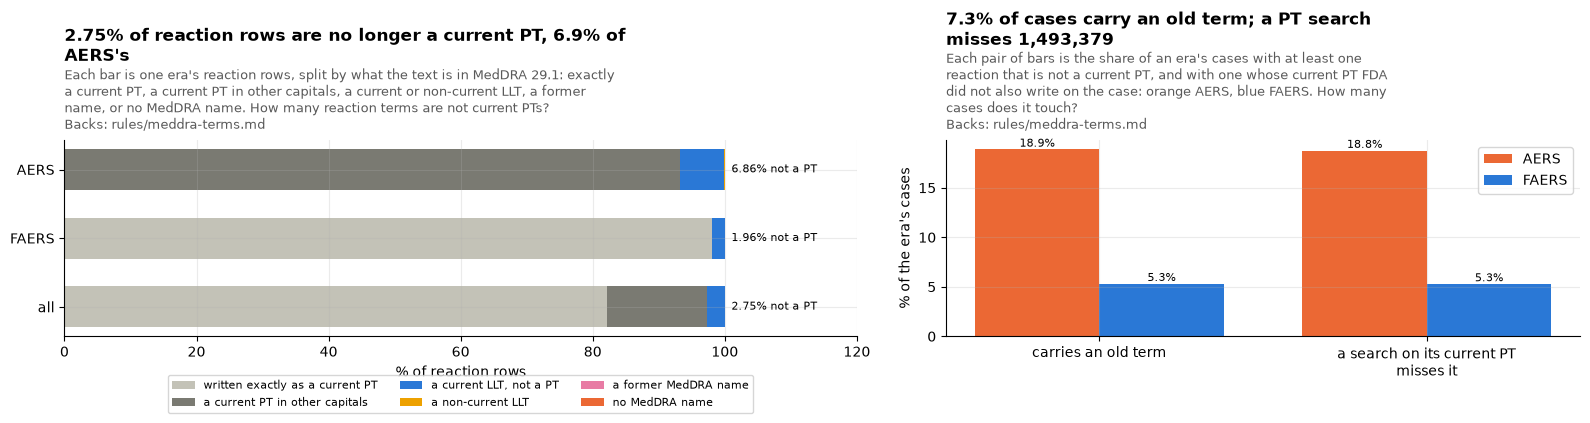

Checked by a second count: 1,687,728 rows not a current PT; 1,502,008 cases carry an old term, 1,493,379 missed by a search on a current PT. Lower level terms in the reaction field that were never a PT: 0. Distinct terms: 25,047, 25,003 of them names in MedDRA 29.1 and 44 former names (39,642 texts as FDA wrote them, 52 of them former names).


era_T,FAERS,AERS,all
class_T,,,
written exactly as a current PT,50460619,8,50460627
a current PT in other capitals,6190,9238834,9245024
"a current LLT, not a PT",1000983,673128,1674111
a non-current LLT,4313,6325,10638
a former MedDRA name,2329,650,2979
no MedDRA name,0,0,0


In [7]:
by_era = q(
    "SELECT era_T, class_T, count(DISTINCT key_T) AS terms, sum(n_rows) AS rows_ FROM rx_T GROUP BY ALL"
)
rows = (
    by_era.pivot_table(index="era_T", columns="class_T", values="rows_", aggfunc="sum")
    .reindex(columns=CLASSES)
    .fillna(0)
)
rows.loc["all"] = rows.sum()
cases = q("""SELECT era_T, count(*) AS cases, count(*) FILTER (WHERE carries_T) AS carries, count(*) FILTER (WHERE missed_T) AS missed,
  count(*) FILTER (WHERE dup_kept_T) AS cases_default, count(*) FILTER (WHERE carries_T AND dup_kept_T) AS carries_default,
  count(*) FILTER (WHERE missed_T AND dup_kept_T) AS missed_default, count(*) FILTER (WHERE merged_T) AS merged
  FROM rcase_T GROUP BY 1""").set_index("era_T")
cases.loc["all"] = cases.sum()
share = 100 * rows.div(rows.sum(axis=1), axis=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["legacy", "faers", "all"]
left = np.zeros(len(order))
for c in CLASSES:
    v = share.loc[order, c].values
    a1.barh(
        ["AERS", "FAERS", "all"][::-1],
        v[::-1],
        left=left[::-1],
        color=COLOR[c],
        label=LABEL[c],
        height=0.6,
    )
    left += v
for i, era in enumerate(order[::-1]):
    a1.text(101, i, f"{share.loc[era, list(OLD)].sum():.2f}% not a PT", va="center", fontsize=8)
a1.set_xlim(0, 120)
a1.set_xlabel("% of reaction rows")
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=8)
title(
    a1,
    f"{share.loc['all', list(OLD)].sum():.2f}% of reaction rows are no longer a current PT, {share.loc['legacy', list(OLD)].sum():.1f}% of AERS's",
    f"Each bar is one era's reaction rows, split by what the text is in MedDRA {VERSION}: exactly a current PT, a current PT in "
    "other capitals, a current or non-current LLT, a former name, or no MedDRA name.",
    "How many reaction terms are not current PTs?",
    "Backs: rules/meddra-terms.md",
)
x = np.arange(2)
w = 0.38
for i, era in enumerate(["legacy", "faers"]):
    vals = [
        100 * cases.loc[era, "carries"] / cases.loc[era, "cases"],
        100 * cases.loc[era, "missed"] / cases.loc[era, "cases"],
    ]
    label_bars(
        a2,
        a2.bar(
            x + (i - 0.5) * w,
            vals,
            w,
            color=ERA[era],
            label={"legacy": "AERS", "faers": "FAERS"}[era],
        ),
        "{:.1f}%",
    )
a2.set_xticks(x)
a2.set_xticklabels(["carries an old term", "a search on its current PT\nmisses it"])
a2.set_ylabel("% of the era's cases")
a2.legend()
title(
    a2,
    f"{100 * cases.loc['all', 'carries'] / cases.loc['all', 'cases']:.1f}% of cases carry an old term; a PT search misses {cases.loc['all', 'missed']:,}",
    "Each pair of bars is the share of an era's cases with at least one reaction that is not a current PT, and with one whose current "
    "PT FDA did not also write on the case: orange AERS, blue FAERS.",
    "How many cases does it touch?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()

# second count, written apart: rows and cases straight from the release, the class looked up in this notebook's own names
now = q("SELECT k, is_pt FROM own_name WHERE NOT former")
pt_keys, names_now = set(now.k[now.is_pt]), set(now.k)
txt = q("SELECT pt AS text, count(*) AS n FROM reac_latest_T WHERE pt IS NOT NULL GROUP BY 1")
txt_key = q("SELECT DISTINCT pt AS text, own_key(pt) AS k FROM reac_latest_T WHERE pt IS NOT NULL")
txt = txt.merge(txt_key, on="text")
not_pt_rows = txt.n[~txt.k.isin(pt_keys)].sum()
assert not_pt_rows == rows.loc["all", list(OLD)].sum()
carry2, missed2, pairs_added2 = one("""
  WITH r AS (SELECT c.case_key_T, n.pt, n.is_pt IS TRUE AS direct FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
             JOIN own_name n ON n.k = own_key(r.pt)),
  p AS (SELECT case_key_T, pt, bool_or(direct) AS d, bool_or(NOT direct) AS o FROM r GROUP BY ALL)
  SELECT count(DISTINCT case_key_T) FILTER (WHERE o), count(DISTINCT case_key_T) FILTER (WHERE o AND NOT d),
         count(*) FILTER (WHERE NOT d) FROM p""")  # the last: case and PT pairs only an old term reaches (section 5)
assert (carry2, missed2) == (cases.loc["all", "carries"], cases.loc["all", "missed"])
never = one(
    "SELECT coalesce(sum(n_rows), 0) FROM rx_T WHERE class_T IN ('llt_current', 'llt_noncurrent') "
    "AND llt_code_T NOT IN (SELECT code FROM own_hist WHERE lvl = 'PT' AND act = 'A')"
)[0]
assert never == 0  # every lower level term in the reaction field was a PT once
old_terms = one(f"SELECT count(DISTINCT key_T) FROM rx_T WHERE class_T IN {OLD}")[0]
terms = one(
    "SELECT count(DISTINCT key_T), count(DISTINCT key_T) FILTER (WHERE class_T = 'former_name'), count(*), "
    "count(*) FILTER (WHERE class_T = 'former_name') FROM rtext_T"
)
print(
    f"Checked by a second count: {not_pt_rows:,} rows not a current PT; {carry2:,} cases carry an old term, {missed2:,} missed by a "
    f"search on a current PT. Lower level terms in the reaction field that were never a PT: {never}. Distinct terms: {terms[0]:,}, "
    f"{terms[0] - terms[1]:,} of them names in MedDRA {VERSION} and {terms[1]} former names ({terms[2]:,} texts as FDA wrote them, {terms[3]} of them former names)."
)
tab = rows.astype(int).rename(columns=LABEL).rename(index={"legacy": "AERS", "faers": "FAERS"})
tab.T

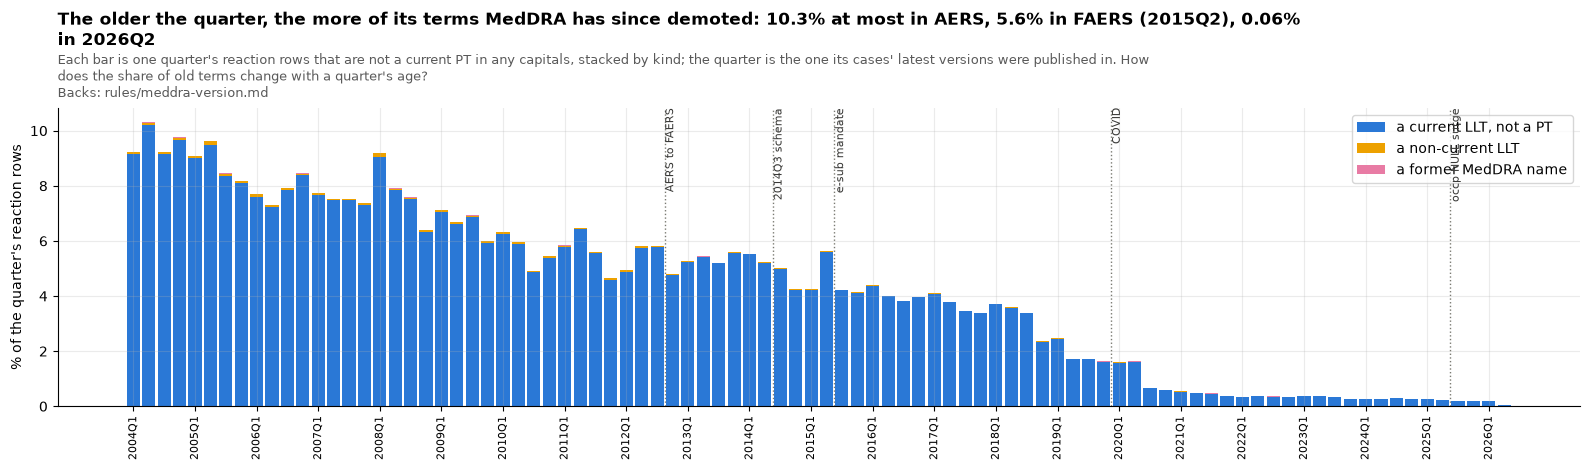

AERS 4.6% to 10.3% (highest 2004Q2); FAERS from 4.8% in 2012Q4, highest 5.62% in 2015Q2, 0.055% in 2026Q2.


**What section 3 shows**, one item per chart:

- **Terms by what they are today.** *Shows:* of 61,393,379 reaction rows on 20,588,478 cases, 82.2% are written exactly as a current PT and 15.1% are one in other capitals (all but 6,190 of them AERS rows); 1,687,728 rows (2.75%), under 2,138 distinct terms, are not a current PT: 6.9% of AERS rows and 2.0% of FAERS rows. None is outside MedDRA: 25,003 of the 25,047 distinct terms are names in 29.1, and the other 44 are former names. Every lower level term among them was a PT when it was coded. *Point:* every old term was a PT when it was coded; splits aside, the gap between FDA's text and today's PTs comes from MedDRA's changes since, not from how FDA coded. *So what:* every old term can be read to its current PT from MedDRA's own files.
- **Cases touched.** *Shows:* 1,502,008 cases (7.3%) carry an old term: 18.9% of AERS cases and 5.3% of FAERS cases. A search on the current PT misses 1,493,379 of them; the other 8,629 also carry their current PT as FDA wrote it. In the explorer's default view (one case per duplicate group): 1,492,555 and 1,483,990. *Point:* a search misses the whole case, so cases, not rows, are what a user feels. *So what:* reactions are counted under their current PT (`rules/meddra-terms.md`).
- **By quarter.** *Shows:* 4.6% to 10.3% of an AERS quarter's rows are old terms (highest 2004Q2); FAERS starts at 4.8%, is highest in 2015Q2 (5.6%) and falls to 0.06% in 2026Q2. *Point:* drift grows with a quarter's age, and also depends on which terms a period used (the peak follows wording MedDRA changed later). *So what:* each MedDRA version adds a little to every older quarter, so the reading is redone with each release's MedDRA version (`rules/meddra-version.md`).

In [8]:
bq = (
    q("SELECT quarter_T, class_T, sum(n_rows) AS n FROM rx_T GROUP BY ALL")
    .pivot_table(index="quarter_T", columns="class_T", values="n", aggfunc="sum")
    .reindex(quarters)
    .fillna(0)
)
bshare = 100 * bq.div(bq.sum(axis=1), axis=0)
old_share = bshare[[c for c in OLD if c in bshare]].sum(axis=1)
legacy_q, faers_q = old_share[old_share.index < "2012q4"], old_share[old_share.index >= "2012q4"]
fig, ax = plt.subplots(figsize=(16, 4.8))
bottom = np.zeros(len(bshare))
for c in OLD:
    if c in bshare:
        ax.bar(
            range(len(bshare)), bshare[c], bottom=bottom, color=COLOR[c], width=0.85, label=LABEL[c]
        )
        bottom += bshare[c].values
ax.set_ylabel("% of the quarter's reaction rows")
ax.legend(loc="upper right")
quarter_ticks(ax, bshare.index)
mark_quarters(ax, bshare.index)
title(
    ax,
    f"The older the quarter, the more of its terms MedDRA has since demoted: {legacy_q.max():.1f}% at most in AERS, {faers_q.max():.1f}% in FAERS ({faers_q.idxmax().upper()}), {old_share.iloc[-1]:.2f}% in {old_share.index[-1].upper()}",
    "Each bar is one quarter's reaction rows that are not a current PT in any capitals, stacked by kind; the quarter is the one "
    "its cases' latest versions were published in.",
    "How does the share of old terms change with a quarter's age?",
    "Backs: rules/meddra-version.md",
)
plt.tight_layout()
plt.show()
print(
    f"AERS {legacy_q.min():.1f}% to {legacy_q.max():.1f}% (highest {legacy_q.idxmax().upper()}); FAERS from {faers_q.iloc[0]:.1f}% "
    f"in {faers_q.index[0].upper()}, highest {faers_q.max():.2f}% in {faers_q.idxmax().upper()}, {faers_q.iloc[-1]:.3f}% in {faers_q.index[-1].upper()}."
)
say(f"""
**What section 3 shows**, one item per chart:

- **Terms by what they are today.** *Shows:* of {TOTAL[0]:,.0f} reaction rows on {CASES:,} cases, {share.loc["all", "pt_exact"]:.1f}% are written exactly as a current PT and {share.loc["all", "pt_case"]:.1f}% are one in other capitals (all but {rows.loc["faers", "pt_case"]:,.0f} of them AERS rows); {rows.loc["all", list(OLD)].sum():,.0f} rows ({share.loc["all", list(OLD)].sum():.2f}%), under {old_terms:,} distinct terms, are not a current PT: {share.loc["legacy", list(OLD)].sum():.1f}% of AERS rows and {share.loc["faers", list(OLD)].sum():.1f}% of FAERS rows. None is outside MedDRA: {terms[0] - terms[1]:,} of the {terms[0]:,} distinct terms are names in {VERSION}, and the other {terms[1]} are former names. Every lower level term among them was a PT when it was coded. *Point:* every old term was a PT when it was coded; splits aside, the gap between FDA's text and today's PTs comes from MedDRA's changes since, not from how FDA coded. *So what:* every old term can be read to its current PT from MedDRA's own files.
- **Cases touched.** *Shows:* {cases.loc["all", "carries"]:,} cases ({100 * cases.loc["all", "carries"] / cases.loc["all", "cases"]:.1f}%) carry an old term: {100 * cases.loc["legacy", "carries"] / cases.loc["legacy", "cases"]:.1f}% of AERS cases and {100 * cases.loc["faers", "carries"] / cases.loc["faers", "cases"]:.1f}% of FAERS cases. A search on the current PT misses {cases.loc["all", "missed"]:,} of them; the other {cases.loc["all", "carries"] - cases.loc["all", "missed"]:,} also carry their current PT as FDA wrote it. In the explorer's default view (one case per duplicate group): {cases.loc["all", "carries_default"]:,} and {cases.loc["all", "missed_default"]:,}. *Point:* a search misses the whole case, so cases, not rows, are what a user feels. *So what:* reactions are counted under their current PT (`rules/meddra-terms.md`).
- **By quarter.** *Shows:* {legacy_q.min():.1f}% to {legacy_q.max():.1f}% of an AERS quarter's rows are old terms (highest {legacy_q.idxmax().upper()}); FAERS starts at {faers_q.iloc[0]:.1f}%, is highest in {faers_q.idxmax().upper()} ({faers_q.max():.1f}%) and falls to {faers_q.iloc[-1]:.2f}% in {faers_q.index[-1].upper()}. *Point:* drift grows with a quarter's age, and also depends on which terms a period used (the peak follows wording MedDRA changed later). *So what:* each MedDRA version adds a little to every older quarter, so the reading is redone with each release's MedDRA version (`rules/meddra-version.md`).
""")

## 4 · Capital letters and MedDRA's spelling

AERS wrote every reaction term in capitals; FAERS writes them as MedDRA spells them. The ladder below matches FDA's text to MedDRA's names more loosely at each step, to show how much of the gap is capitals alone. Then the display: MedDRA's spelling is sentence case, not title case, so it cannot be made from capitals by a rule; the release instead gives each AERS term the spelling FAERS itself uses for it (`pt_spelling_T`, rule `legacy-term-spelling`), with FDA's capitals kept beside it.

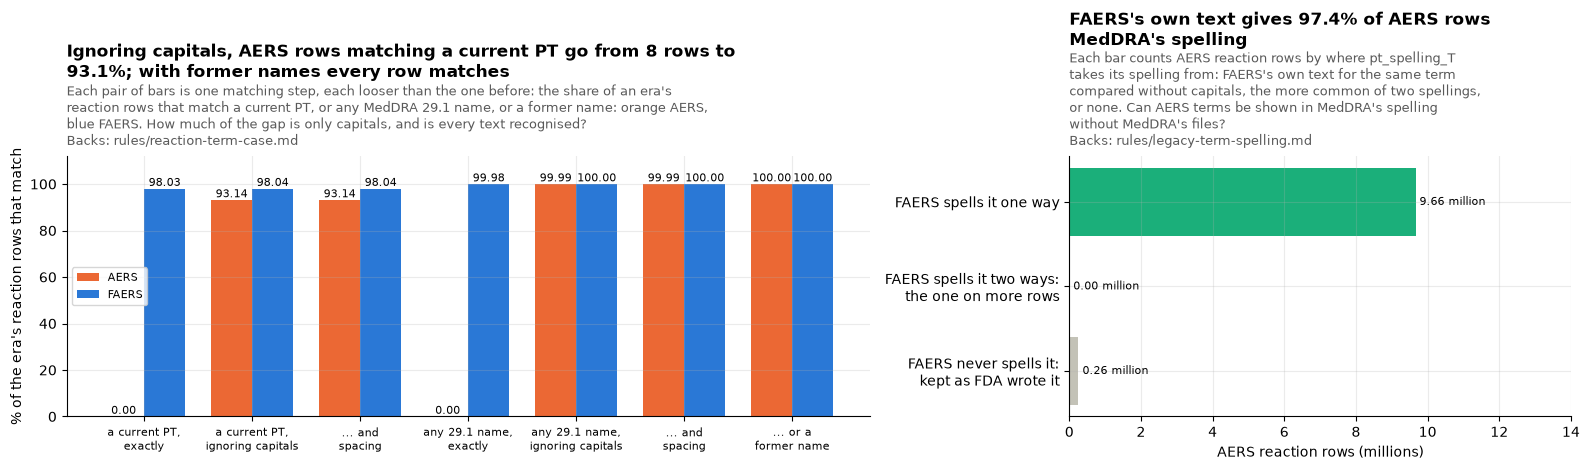

AERS: 8 of 9,918,945 rows match a current PT exactly, 93.1% ignoring capitals, 100.0% with former names. FAERS: 98.03% exactly. FAERS rows in capitals: 6,190, 6,177 of them in 2012Q4 to 2013Q2 and 13 later. Of 24,748 PT names of more than one word, 24,654 write a later word in small letters (sentence case).


**What section 4 shows**, one item per chart:

- **The matching ladder.** *Shows:* 8 of 9,918,945 AERS rows match a current PT letter for letter, 93.1% once capitals are ignored, and every row once former names are allowed; spacing never matters. FAERS matches 98.03% exactly; its 6,190 rows in capitals sit in 2012Q4 to 2013Q2, the quarters that carried AERS cases over (6,177), and 13 later. *Point:* every text is recognised. Matching every text is not the same as every reaction being right: section 5 shows what the mapping cannot undo, and FDA does not publish the reporter's own words to check its coding against. *So what:* search, the duplicate key and the mapping ignore capitals already (`rules/reaction-term-case.md`); what is left is display.
- **MedDRA's spelling from FAERS's own text.** *Shows:* 24,654 of 24,748 PT names of more than one word are in sentence case, so capitals cannot be turned into MedDRA's spelling by a rule. FAERS spells the same term for 97.4% of AERS rows (9,662,115 of 9,918,945); 2 terms are spelled two ways (13 rows), and 256,830 rows, under 1,460 texts FAERS never spells, stay as FDA wrote them. For AERS indications the share is 99.1%. *Point:* nearly every AERS term can be shown as MedDRA writes it with nothing licensed. *So what:* `pt_spelling_T` and `indi_pt_spelling_T` are public columns beside FDA's text, which stays as written (`rules/legacy-term-spelling.md`).

In [9]:
ladder = (
    q("""
SELECT era_T, sum(n_rows) AS total,
  sum(n_rows) FILTER (WHERE text IN (SELECT name FROM own_pt)) AS pt_exact,
  sum(n_rows) FILTER (WHERE lower(text) IN (SELECT lower(name) FROM own_pt)) AS pt_capitals,
  sum(n_rows) FILTER (WHERE own_key(text) IN (SELECT own_key(name) FROM own_pt)) AS pt_spacing,
  sum(n_rows) FILTER (WHERE text IN (SELECT name FROM own_llt)) AS any_exact,
  sum(n_rows) FILTER (WHERE lower(text) IN (SELECT lower(name) FROM own_llt)) AS any_capitals,
  sum(n_rows) FILTER (WHERE own_key(text) IN (SELECT k FROM own_name WHERE NOT former)) AS any_spacing,
  sum(n_rows) FILTER (WHERE own_key(text) IN (SELECT k FROM own_name)) AS any_former
FROM rq_T GROUP BY 1""")
    .set_index("era_T")
    .loc[["legacy", "faers"]]
)
STEPS = [
    ("pt_exact", "a current PT,\nexactly"),
    ("pt_capitals", "a current PT,\nignoring capitals"),
    ("pt_spacing", "... and\nspacing"),
    ("any_exact", f"any {VERSION} name,\nexactly"),
    ("any_capitals", f"any {VERSION} name,\nignoring capitals"),
    ("any_spacing", "... and\nspacing"),
    ("any_former", "... or a\nformer name"),
]
# the build's spelling step, on each AERS text
for statement in spelling.spelling_tables():
    con.execute(statement)
shown, join = spelling.column("reac")
spelled = q(
    f"SELECT a.era_T, a.pt, a.n_rows{shown} FROM (SELECT era_T, text AS pt, sum(n_rows) AS n_rows FROM rq_T GROUP BY ALL) a{join}"
)
aers = spelled[spelled.era_T == "legacy"].assign(k=lambda d: d.pt.str.lower())
twice = set(
    q(
        "SELECT lower(pt) AS k FROM (SELECT DISTINCT pt FROM reac WHERE era_T = 'faers' AND regexp_matches(pt, '[a-z]')) GROUP BY 1 HAVING count(*) > 1"
    ).k
)
outcome = pd.Series(
    {
        "FAERS spells it one way": aers.n_rows[
            (aers.pt_spelling_T != aers.pt) & ~aers.k.isin(twice)
        ].sum(),
        "FAERS spells it two ways:\nthe one on more rows": aers.n_rows[
            (aers.pt_spelling_T != aers.pt) & aers.k.isin(twice)
        ].sum(),
        "FAERS never spells it:\nkept as FDA wrote it": aers.n_rows[
            aers.pt_spelling_T == aers.pt
        ].sum(),
    }
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(len(STEPS))
w = 0.38
for i, era in enumerate(["legacy", "faers"]):
    vals = 100 * ladder.loc[era, [s for s, _ in STEPS]] / ladder.loc[era, "total"]
    label_bars(
        a1,
        a1.bar(
            x + (i - 0.5) * w,
            vals,
            w,
            color=ERA[era],
            label={"legacy": "AERS", "faers": "FAERS"}[era],
        ),
        "{:.2f}",
    )
a1.set_xticks(x)
a1.set_xticklabels([lbl for _, lbl in STEPS], fontsize=8)
a1.set_ylabel("% of the era's reaction rows that match")
a1.set_ylim(0, 112)
a1.legend(loc="center left", fontsize=8)
title(
    a1,
    f"Ignoring capitals, AERS rows matching a current PT go from {ladder.loc['legacy', 'pt_exact']:,.0f} rows to {100 * ladder.loc['legacy', 'pt_capitals'] / ladder.loc['legacy', 'total']:.1f}%; with former names every row matches",
    "Each pair of bars is one matching step, each looser than the one before: the share of an era's reaction rows that match a "
    f"current PT, or any MedDRA {VERSION} name, or a former name: orange AERS, blue FAERS.",
    "How much of the gap is only capitals, and is every text recognised?",
    "Backs: rules/reaction-term-case.md",
)
bars = a2.barh(
    outcome.index[::-1], outcome.values[::-1] / 1e6, color=[SERIES[7], SERIES[3], SERIES[2]]
)
label_bars(a2, bars, "{:,.2f} million", horizontal=True)
a2.set_xlim(0, outcome.max() / 1e6 * 1.45)
a2.set_xlabel("AERS reaction rows (millions)")
title(
    a2,
    f"FAERS's own text gives {100 * outcome.iloc[:2].sum() / outcome.sum():.1f}% of AERS rows MedDRA's spelling",
    "Each bar counts AERS reaction rows by where pt_spelling_T takes its spelling from: FAERS's own text for the same term "
    "compared without capitals, the more common of two spellings, or none.",
    "Can AERS terms be shown in MedDRA's spelling without MedDRA's files?",
    "Backs: rules/legacy-term-spelling.md",
)
plt.tight_layout()
plt.show()
# second count, written apart: FAERS's mixed-case spellings in Python, against the build's column
fa = {
    t.lower()
    for t in q("SELECT DISTINCT pt FROM reac WHERE era_T = 'faers'").pt.dropna()
    if any(ch.islower() for ch in t)
}
assert aers.n_rows[aers.k.isin(fa)].sum() == outcome.iloc[:2].sum()
caps = (
    q(
        "SELECT quarter_T <= '2013q2' AS carried_over, sum(n_rows) AS n FROM rx_T WHERE era_T = 'faers' AND class_T = 'pt_case' GROUP BY 1"
    )
    .set_index("carried_over")
    .n
)
names = q("SELECT name FROM own_pt").name
words = names[names.str.contains(" ")].str.split(" ").str[1:]
sentence = words.apply(lambda ws: any(w[:1].islower() for w in ws)).sum()
lg = ladder.loc["legacy"]
fg = ladder.loc["faers"]
print(
    f"AERS: {lg.pt_exact:,.0f} of {lg.total:,.0f} rows match a current PT exactly, {100 * lg.pt_capitals / lg.total:.1f}% ignoring capitals, "
    f"{100 * lg.any_former / lg.total:.1f}% with former names. FAERS: {100 * fg.pt_exact / fg.total:.2f}% exactly. "
    f"FAERS rows in capitals: {caps.sum():,.0f}, {caps.get(True, 0):,.0f} of them in 2012Q4 to 2013Q2 and {caps.get(False, 0):,.0f} later. "
    f"Of {len(words):,} PT names of more than one word, {sentence:,} write a later word in small letters (sentence case)."
)
ishown, ijoin = spelling.column("indi")
ispelled = q(
    f"SELECT a.indi_pt, a.n{ishown} FROM (SELECT era_T, indi_pt, count(*) AS n FROM indi_latest_T WHERE era_T = 'legacy' "
    f"AND indi_pt IS NOT NULL GROUP BY ALL) a{ijoin}"
)
indi_spelled = ispelled.n[ispelled.indi_pt_spelling_T != ispelled.indi_pt].sum() / ispelled.n.sum()
say(f"""
**What section 4 shows**, one item per chart:

- **The matching ladder.** *Shows:* {lg.pt_exact:,.0f} of {lg.total:,.0f} AERS rows match a current PT letter for letter, {100 * lg.pt_capitals / lg.total:.1f}% once capitals are ignored, and every row once former names are allowed; spacing never matters. FAERS matches {100 * fg.pt_exact / fg.total:.2f}% exactly; its {caps.sum():,.0f} rows in capitals sit in 2012Q4 to 2013Q2, the quarters that carried AERS cases over ({caps.get(True, 0):,.0f}), and {caps.get(False, 0):,.0f} later. *Point:* every text is recognised. Matching every text is not the same as every reaction being right: section 5 shows what the mapping cannot undo, and FDA does not publish the reporter's own words to check its coding against. *So what:* search, the duplicate key and the mapping ignore capitals already (`rules/reaction-term-case.md`); what is left is display.
- **MedDRA's spelling from FAERS's own text.** *Shows:* {sentence:,} of {len(words):,} PT names of more than one word are in sentence case, so capitals cannot be turned into MedDRA's spelling by a rule. FAERS spells the same term for {100 * outcome.iloc[:2].sum() / outcome.sum():.1f}% of AERS rows ({outcome.iloc[:2].sum():,.0f} of {outcome.sum():,.0f}); {len(twice)} terms are spelled two ways ({outcome.iloc[1]:,.0f} rows), and {outcome.iloc[2]:,.0f} rows, under {aers[aers.pt_spelling_T == aers.pt].pt.nunique():,} texts FAERS never spells, stay as FDA wrote them. For AERS indications the share is {100 * indi_spelled:.1f}%. *Point:* nearly every AERS term can be shown as MedDRA writes it with nothing licensed. *So what:* `pt_spelling_T` and `indi_pt_spelling_T` are public columns beside FDA's text, which stays as written (`rules/legacy-term-spelling.md`).
""")

## 5 · How old terms map to current PTs, and what mapping cannot do

**Where the mapping comes from.** MedDRA's own term file (`llt.asc`): every term's line names its current PT, so a lower level term leads to its PT in one step, and a former name leads, through the history file, to its term's code and so to its PT. Nothing is our judgement. A case can meet the same PT twice, through an old term and the term itself, so counts per PT count each case once.

In [10]:
con.execute(f"""CREATE TABLE old_case_T AS        -- each case and old term: few rows, so the shares below are exact
SELECT DISTINCT c.case_key_T, t.key_T, t.class_T, t.pt_code_T
FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T) JOIN rtext_T t ON t.text = r.pt
WHERE t.class_T IN {OLD}""")
mp = q("""SELECT o.key_T AS old_term, p.pt_name AS current_pt, o.class_T, count(*) AS cases
          FROM old_case_T o JOIN meddra_pt p ON p.pt_code = o.pt_code_T GROUP BY ALL ORDER BY cases DESC, old_term""")
with_old = one("SELECT count(DISTINCT case_key_T) FROM old_case_T")[0]
reach = {
    n: one(
        f"SELECT count(DISTINCT case_key_T) FROM old_case_T WHERE key_T IN "
        f"(SELECT key_T FROM old_case_T GROUP BY 1 ORDER BY count(*) DESC, key_T LIMIT {n})"
    )[0]
    for n in (15, 100)
}
top = mp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.barh(
    top.old_term + "  >  " + top.current_pt, top.cases / 1e3, color=[COLOR[c] for c in top.class_T]
)
label_bars(ax, bars, "{:,.1f}k", horizontal=True)
ax.set_xlabel("cases (thousands)")
ax.tick_params(axis="y", labelsize=8)
ax.legend(
    handles=[Patch(color=COLOR[c], label=LABEL[c]) for c in OLD if c in set(mp.class_T)],
    loc="lower right",
)
title(
    ax,
    f"The 15 largest of {len(mp):,} mappings reach {100 * reach[15] / with_old:.1f}% of the cases with an old term",
    "Each bar is one old reaction term and the current PT MedDRA's term file gives it, the 15 on the most cases, coloured by "
    "kind; a case counts once per bar.",
    "Which mappings matter most?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
# second count, written apart: case and old-term pairs from this notebook's own names
pairs2 = one("""SELECT count(*) FROM (SELECT DISTINCT c.case_key_T, n.k FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
                JOIN own_name n ON n.k = own_key(r.pt) WHERE NOT coalesce(n.is_pt, FALSE))""")[0]
assert pairs2 == mp.cases.sum()
print(
    f"{len(mp):,} old terms map into {mp.current_pt.nunique():,} current PTs. The 15 largest reach {reach[15]:,} of the {with_old:,} cases "
    f"with an old term ({100 * reach[15] / with_old:.1f}%), the 100 largest {100 * reach[100] / with_old:.1f}% "
    f"(as shares of case and term pairs: {100 * mp.head(15).cases.sum() / mp.cases.sum():.1f}% and {100 * mp.head(100).cases.sum() / mp.cases.sum():.1f}%)."
)

Output not shown: it contains MedDRA content beyond the Preferred Term names (the hierarchy, SMQs or codes). MedDRA is licensed by the MSSO, so we cannot publish it. To see this output, run the notebook with your own MedDRA files; you need a MedDRA subscription from the MSSO.

### What a search on a current PT misses today

A search on a current PT finds the cases whose reaction text is that PT, in any capitals. Read to current PTs, it also finds the cases coded under the PT's old terms. The left chart shows the PTs that gain the most cases; the right one how large the gain is, as a share of what a search finds today. A PT that only old terms reach has its own bar: no FAERS text names it yet.

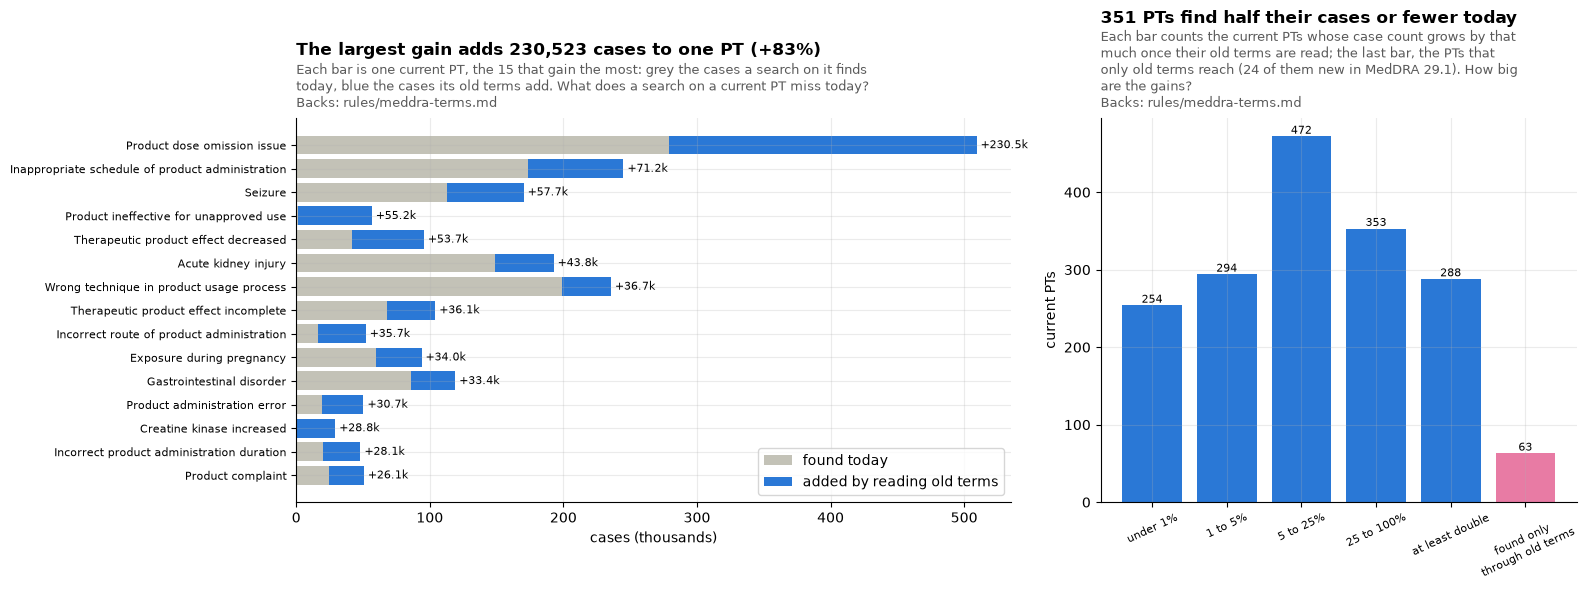

1,724 of 22,972 PTs seen gain cases; 288 at least double, 268 more than double, 63 only through old terms (24 new in 29.1, holding 12,653 of their 13,167 cases). Case and PT pairs added: 1,674,218.


In [11]:
gain = q("""
WITH cp AS (SELECT c.case_key_T, t.pt_code_T, bool_or(t.class_T IN ('pt_exact', 'pt_case')) AS direct
            FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T) JOIN rtext_T t ON t.text = r.pt
            WHERE t.pt_code_T IS NOT NULL GROUP BY ALL)
SELECT p.pt_code, p.pt_name, count(*) FILTER (WHERE direct) AS today, count(*) AS mapped
FROM cp JOIN meddra_pt p ON p.pt_code = cp.pt_code_T GROUP BY ALL""")
gain["added"] = gain.mapped - gain.today
hit = gain[gain.added > 0].copy()
hit["pct"] = 100 * hit.added / hit.today.where(hit.today > 0)
new_here = set(
    q(f"SELECT code FROM own_hist WHERE lvl = 'PT' AND act = 'A' AND ver = '{VERSION}'").code
)
only = hit[hit.today == 0]
g = hit.sort_values("added", ascending=False).head(15).iloc[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.5, 1]})
a1.barh(g.pt_name, g.today / 1e3, color=SERIES[7], label="found today")
label_bars(
    a1,
    a1.barh(
        g.pt_name,
        g.added / 1e3,
        left=g.today / 1e3,
        color=SERIES[0],
        label="added by reading old terms",
    ),
    "+{:,.1f}k",
    horizontal=True,
)
a1.set_xlabel("cases (thousands)")
a1.legend(loc="lower right")
a1.tick_params(axis="y", labelsize=8)
best = hit.sort_values("added").iloc[-1]
title(
    a1,
    f"The largest gain adds {int(best.added):,} cases to one PT (+{best.pct:.0f}%)",
    "Each bar is one current PT, the 15 that gain the most: grey the cases a search on it finds today, blue the cases its old "
    "terms add.",
    "What does a search on a current PT miss today?",
    "Backs: rules/meddra-terms.md",
)
labels = [
    "under 1%",
    "1 to 5%",
    "5 to 25%",
    "25 to 100%",
    "at least double",
    "found only\nthrough old terms",
]
band = (
    pd.cut(hit.pct.dropna(), [0, 1, 5, 25, 100, np.inf], labels=labels[:5], right=False)
    .value_counts()
    .reindex(labels[:5])
)
band[labels[5]] = len(only)
bars = a2.bar(labels, band.values, color=[SERIES[0]] * 5 + [SERIES[4]])
label_bars(a2, bars)
a2.tick_params(axis="x", rotation=25, labelsize=8)
a2.set_ylabel("current PTs")
title(
    a2,
    f"{band['at least double'] + len(only):,} PTs find half their cases or fewer today",
    "Each bar counts the current PTs whose case count grows by that much once their old terms are read; the last bar, the PTs "
    f"that only old terms reach ({only.pt_code.isin(new_here).sum()} of them new in MedDRA {VERSION}).",
    "How big are the gains?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
assert pairs_added2 == hit.added.sum()  # the second count of section 3
print(
    f"{len(hit):,} of {len(gain):,} PTs seen gain cases; {band['at least double']:,} at least double, {(hit.pct > 100).sum():,} more than "
    f"double, {len(only)} only through old terms ({only.pt_code.isin(new_here).sum()} new in {VERSION}, holding "
    f"{only[only.pt_code.isin(new_here)].mapped.sum():,} of their {only.mapped.sum():,} cases). Case and PT pairs added: {hit.added.sum():,}."
)

### When the old terms stopped being PTs

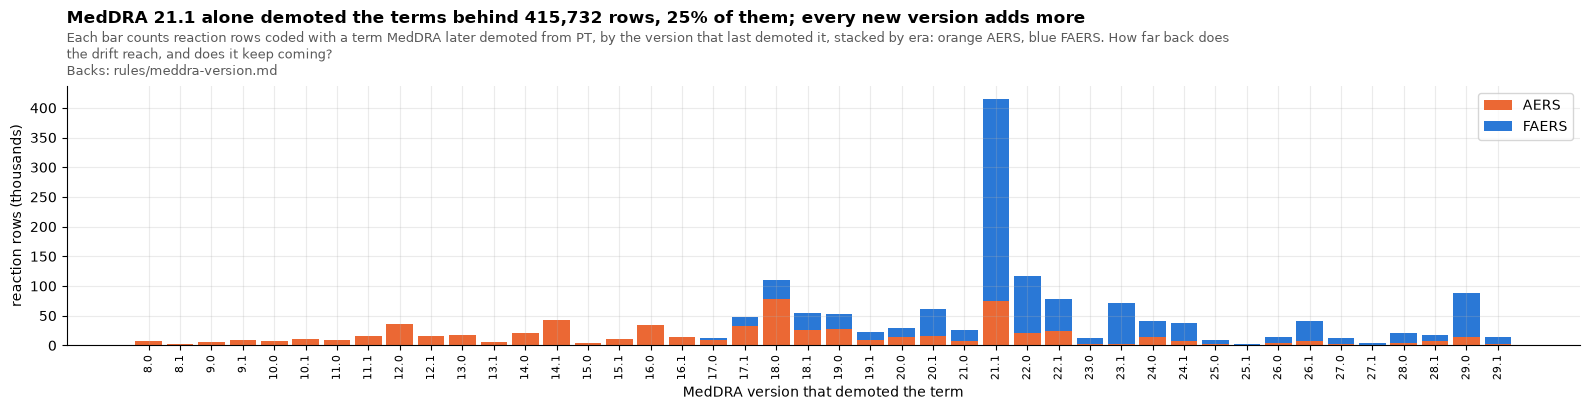

Demoted in the last four versions (28.0 to 29.1): 140,753 rows; in 29.1 alone: 14,719.


In [12]:
dv = (
    q("""SELECT r.era_T, d.v, sum(r.n_rows) AS n FROM rx_T r
          JOIN (SELECT code, max(v) FILTER (WHERE act = 'D') AS v FROM own_hist WHERE lvl = 'PT' GROUP BY 1) d ON d.code = r.llt_code_T
          WHERE r.class_T IN ('llt_current', 'llt_noncurrent') GROUP BY ALL""")
    .pivot_table(index="v", columns="era_T", values="n", aggfunc="sum")
    .fillna(0)
    .sort_index()
)
by_v = dv.sum(axis=1)


def vlabel(v):
    return f"{v // 10}.{v % 10}"


fig, ax = plt.subplots(figsize=(16, 4.2))
x = np.arange(len(dv))
bottom = np.zeros(len(dv))
for era in ["legacy", "faers"]:
    ax.bar(
        x,
        dv[era] / 1e3,
        bottom=bottom,
        color=ERA[era],
        width=0.85,
        label={"legacy": "AERS", "faers": "FAERS"}[era],
    )
    bottom += dv[era].values / 1e3
ax.set_xticks(x)
ax.set_xticklabels([vlabel(int(v)) for v in dv.index], rotation=90, fontsize=8)
ax.set_xlabel("MedDRA version that demoted the term")
ax.set_ylabel("reaction rows (thousands)")
ax.legend()
title(
    ax,
    f"MedDRA {vlabel(int(by_v.idxmax()))} alone demoted the terms behind {by_v.max():,.0f} rows, {100 * by_v.max() / by_v.sum():.0f}% of them; every new version adds more",
    "Each bar counts reaction rows coded with a term MedDRA later demoted from PT, by the version that last demoted it, stacked "
    "by era: orange AERS, blue FAERS.",
    "How far back does the drift reach, and does it keep coming?",
    "Backs: rules/meddra-version.md",
)
plt.tight_layout()
plt.show()
newest_four = [int(ver.replace(".", "")) for ver in versions[-4:]]
print(
    f"Demoted in the last four versions ({versions[-4]} to {versions[-1]}): {by_v[by_v.index.isin(newest_four)].sum():,.0f} rows; "
    f"in {VERSION} alone: {by_v.get(int(VERSION.replace('.', '')), 0):,.0f}."
)

### What mapping cannot undo: splits and re-promotions

Mapping moves a term MedDRA demoted under the PT it points to today. It cannot go the other way. When MedDRA makes a new, narrower PT out of a term that sat under a broader one (a **split**), the reports coded before stay under the broader PT, and no file says which of them the new PT would have taken. The same happens when MedDRA demotes a PT and later makes it a PT again (a **re-promotion**): the quarters coded in between have none of it. Both are counted here from the history file: a split is a current PT whose code was a lower level term before it was made a PT, in a version FDA coded with, and into which no older FAERS term maps; a re-promotion, a code demoted and made a PT again within those versions.

In [13]:
con.register(
    "coded_df",
    pd.DataFrame({"quarter_T": coded.index, "v": [int(ver.replace(".", "")) for ver in coded]}),
)
first_v, last_v = (
    int(min(coded, key=vi.get).replace(".", "")),
    int(max(coded, key=vi.get).replace(".", "")),
)
splits = q(f"""
WITH f AS (SELECT code, min(v) FILTER (WHERE lvl = 'LLT') AS llt_first, min(v) FILTER (WHERE lvl = 'PT' AND act = 'A') AS pt_first
           FROM own_hist GROUP BY 1)
SELECT f.code, f.pt_first FROM f JOIN own_pt p USING (code)
WHERE f.llt_first < f.pt_first AND f.pt_first > {first_v} AND f.pt_first <= {last_v}
  AND f.code NOT IN (SELECT pt_code_T FROM rtext_T WHERE class_T IN {OLD} AND pt_code_T IS NOT NULL)""")
con.register("splits_df", splits)
split_rows = q("""SELECT s.code, sum(r.n_rows) FILTER (WHERE c.v < s.pt_first) AS before_, sum(r.n_rows) FILTER (WHERE c.v >= s.pt_first) AS after_
  FROM splits_df s JOIN rx_T r ON r.pt_code_T = s.code AND r.class_T IN ('pt_exact', 'pt_case') JOIN coded_df c USING (quarter_T) GROUP BY 1""").fillna(
    0
)
before_q = q(
    "SELECT s.code, count(*) AS quarters_before FROM splits_df s JOIN coded_df c ON c.v < s.pt_first GROUP BY 1"
)
# re-promotions inside the data: the hole they leave, and where its reports went
rep_codes = q(f"""
WITH e AS (SELECT code, v, act FROM own_hist WHERE lvl = 'PT' AND act IN ('A', 'D')),
d AS (SELECT a.code, a.v AS down, min(b.v) AS up FROM e a JOIN e b ON b.code = a.code AND b.act = 'A' AND b.v > a.v
      WHERE a.act = 'D' GROUP BY ALL)
SELECT * FROM d WHERE down > {first_v} AND up <= {last_v}""")
con.register("rep_codes_df", rep_codes)
# the re-promoted PT with the most rows whose gap holds a quarter, and the codes MedDRA demoted with it
holes = q("""SELECT d.code, d.down, d.up, sum(r.n_rows) AS rows_ FROM rep_codes_df d
             JOIN rx_T r ON r.pt_code_T = d.code AND r.class_T IN ('pt_exact', 'pt_case')
             WHERE EXISTS (SELECT 1 FROM coded_df c WHERE c.v >= d.down AND c.v < d.up)
             GROUP BY ALL ORDER BY rows_ DESC LIMIT 1""").iloc[0]
gap = q(
    f"SELECT quarter_T FROM coded_df WHERE v >= {holes.down} AND v < {holes.up} ORDER BY 1"
).quarter_T.tolist()
gone = rep_codes[(rep_codes.down == holes.down) & (rep_codes.up == holes.up)].code.tolist()
# the SMQ holding every re-promoted PT of that hole, and its PT whose rows jump in the hole's quarters
smqs = q(f"""SELECT smq_code FROM meddra_smq_content WHERE term_level = '4' AND term_code IN ({", ".join(repr(c) for c in gone)})
             GROUP BY 1 HAVING count(DISTINCT term_code) = {len(gone)}""").smq_code.tolist()
assert smqs, "an SMQ holds every PT of the hole"
idx = quarters.index(gap[0])
side = [quarters[idx - 1], quarters[quarters.index(gap[-1]) + 1]]
jump = q(f"""SELECT c.smq_code, r.pt_code_T, sum(r.n_rows) FILTER (WHERE r.quarter_T IN ({", ".join(repr(x) for x in gap)})) AS in_gap,
               sum(r.n_rows) FILTER (WHERE r.quarter_T IN ({", ".join(repr(x) for x in side)})) / 2 AS beside
             FROM meddra_smq_content c JOIN rx_T r ON r.pt_code_T = c.term_code AND r.class_T IN ('pt_exact', 'pt_case')
             WHERE c.term_level = '4' AND c.smq_code IN ({", ".join(repr(x) for x in smqs)}) AND c.term_code NOT IN ({", ".join(repr(x) for x in gone)})
             GROUP BY ALL""").fillna(0)
jump["excess"] = jump.in_gap - jump.beside
took = jump.sort_values(["excess", "pt_code_T"]).iloc[-1]  # the PT whose rows jump most in the hole
# the most specific SMQ (fewest PTs) that holds the gone PTs and that one
smq_name = one(f"""SELECT l.smq_name FROM meddra_smq_content c JOIN meddra_smq_list l USING (smq_code)
                   WHERE c.term_level = '4' AND c.smq_code IN ({", ".join(repr(x) for x in smqs)})
                   GROUP BY ALL HAVING bool_or(c.term_code = '{took.pt_code_T}')
                   ORDER BY count(DISTINCT c.term_code), l.smq_name LIMIT 1""")[0]
shown_codes = gone + [took.pt_code_T]
window = quarters[max(0, idx - 3) : quarters.index(gap[-1]) + 4]
series = (
    q(f"""SELECT r.quarter_T, p.pt_name, sum(r.n_rows) AS n FROM rx_T r JOIN meddra_pt p ON p.pt_code = r.pt_code_T
               WHERE r.pt_code_T IN ({", ".join(repr(x) for x in shown_codes)}) AND r.class_T IN ('pt_exact', 'pt_case')
               AND r.quarter_T IN ({", ".join(repr(x) for x in window)}) GROUP BY ALL""")
    .pivot_table(index="quarter_T", columns="pt_name", values="n", aggfunc="sum")
    .reindex(window)
    .fillna(0)
)
series = series[series.sum().sort_values(ascending=False).index]
took_name = one(f"SELECT pt_name FROM meddra_pt WHERE pt_code = '{took.pt_code_T}'")[0]
in_smq = one(f"""SELECT count(DISTINCT c.case_key_T) FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
                 JOIN rtext_T t ON t.text = r.pt WHERE t.pt_code_T IN ({", ".join(repr(x) for x in shown_codes)})""")[
    0
]
took_cases = one(f"""SELECT count(DISTINCT c.case_key_T) FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
                     JOIN rtext_T t ON t.text = r.pt WHERE t.pt_code_T = '{took.pt_code_T}' AND r.quarter_T IN ({", ".join(repr(x) for x in gap)})""")[
    0
]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
counts = pd.Series(
    {
        "in the quarters before\nits promotion": split_rows.before_.sum(),
        "since it became a PT": split_rows.after_.sum(),
    }
)
label_bars(a1, a1.bar(counts.index, counts.values, color=[SERIES[1], SERIES[0]], width=0.55))
a1.set_yscale("log")
a1.set_ylim(bottom=0.5)
a1.set_ylabel("reaction rows (log scale)")
title(
    a1,
    f"{len(split_rows):,} PTs split from a broader term hold {counts.iloc[1]:,.0f} rows since, and {counts.iloc[0]:,.0f} before",
    f"The two bars count the reaction rows of the {len(split_rows):,} current PTs MedDRA made from an existing lower level term in "
    "a version FDA coded with, into which no older FAERS term maps: before and after each was made a PT.",
    "What does a search on a split PT find from before the split?",
    "Backs: rules/meddra-terms.md",
)
bottom = np.zeros(len(series))
for i, col in enumerate(series.columns):
    a2.bar(
        range(len(series)),
        series[col],
        bottom=bottom,
        color=SERIES[i % len(SERIES)],
        label=col,
        width=0.8,
    )
    bottom += series[col].values
a2.set_xticks(range(len(series)))
a2.set_xticklabels([x.upper() for x in series.index], fontsize=8)
a2.legend(fontsize=8, loc="upper left")
a2.set_ylabel("reaction rows")
title(
    a2,
    f"In {', '.join(x.upper() for x in gap)}, the {len(gone)} PTs MedDRA briefly demoted have no rows; another PT of the same SMQ takes them",
    f"Each bar is one quarter's reaction rows under the PTs MedDRA demoted in {vlabel(int(holes.down))} and made PTs again in "
    f"{vlabel(int(holes.up))}, and under the PT of the same SMQ whose rows jump in between.",
    "Where do reports go when MedDRA demotes a PT and brings it back?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
print(
    f"Splits: {len(splits):,} current PTs were made from an existing lower level term in a version after {vlabel(first_v)}, up to {vlabel(last_v)}, with no "
    f"older FAERS term mapping into them; {len(split_rows):,} appear in FAERS, on {counts.iloc[1]:,.0f} rows after the split and "
    f"{counts.iloc[0]:,.0f} before, over a median {before_q.quarters_before.median():.0f} quarters before. Re-promotions inside the data: "
    f"{rep_codes.code.nunique():,} codes. The largest hole is {', '.join(x.upper() for x in gap)} ({vlabel(int(holes.down))}): "
    f"{took_name!r} holds {took.in_gap:,.0f} rows there against {took.beside:,.0f} a quarter either side; its {took_cases:,} cases "
    f"there are {100 * took_cases / in_smq:.2f}% of the {in_smq:,} cases under these PTs, all of which {smq_name!r} holds."
)

Output not shown: it contains MedDRA content beyond the Preferred Term names (the hierarchy, SMQs or codes). MedDRA is licensed by the MSSO, so we cannot publish it. To see this output, run the notebook with your own MedDRA files; you need a MedDRA subscription from the MSSO.

In [14]:
say(f"""
**What section 5 shows**, one item per chart:

- **The largest mappings.** *Shows:* {len(mp):,} old terms map into {mp.current_pt.nunique():,} current PTs, each by MedDRA's own term file. The 15 largest reach {100 * reach[15] / with_old:.1f}% of the {with_old:,} cases with an old term, the 100 largest {100 * reach[100] / with_old:.1f}%; most are lower level terms, and wording MedDRA changed from "drug" to "product" leads. *Point:* where mapping matters, it matters a lot, and clinically important PTs are split today between an old name and a new one. *So what:* reactions are read to their current PT, and a count per PT counts each case once ({cases.loc["all", "merged"]:,} cases have two reactions that meet in one PT, mostly an old term and its current PT both on the report).
- **What a search misses.** *Shows:* {len(hit):,} of {len(gain):,} PTs gain cases, {hit.added.sum():,} case and PT pairs in all; {band["at least double"]:,} PTs at least double and {len(only)} are reached only through old terms, {only.pt_code.isin(new_here).sum()} of them new in MedDRA {VERSION} (no quarter is coded in {VERSION} yet). For {band["at least double"] + len(only):,} PTs a search today finds half the cases or fewer. *Point:* the cases a user misses concentrate on a few PTs, and the newest version adds PTs no file names yet. *So what:* statistics, label flags and search count current PTs (`rules/meddra-terms.md`).
- **When the terms were demoted.** *Shows:* MedDRA {vlabel(int(by_v.idxmax()))} demoted the terms behind {by_v.max():,.0f} rows ({100 * by_v.max() / by_v.sum():.0f}%); the last four versions demoted the terms behind {by_v[by_v.index.isin(newest_four)].sum():,.0f} rows, {VERSION} alone {by_v.get(int(VERSION.replace(".", "")), 0):,.0f}. *Point:* drift reaches back to the first files and keeps coming. *So what:* the reading is redone with each release's MedDRA version (`rules/meddra-version.md`).
- **Splits and re-promotions.** *Shows:* {len(split_rows):,} PTs MedDRA made out of an existing lower level term while FAERS was being coded, with no older term mapping into them, hold {counts.iloc[1]:,.0f} rows since and {counts.iloc[0]:,.0f} before: a search on them finds nothing from the quarters before their split, whose reports sit under a broader PT the files do not name. How many such reports there were cannot be counted from MedDRA's files, because the history file does not record which PT a term sat under before; so no estimate is given. {rep_codes.code.nunique():,} codes were demoted and made PTs again inside the data. In the largest case, the quarter coded in {vlabel(int(holes.down))} has none of {len(gone)} PTs, and a PT of the same SMQ holds {took.in_gap:,.0f} rows there against {took.beside:,.0f} a quarter either side: {took_cases:,} cases, {100 * took_cases / in_smq:.2f}% of the cases under these PTs. *Point:* matching every text is not the same as every report being under the term it would get today. *So what:* the methods page says so, and a careful search uses MedDRA's SMQ, which holds the terms of a split together (`rules/meddra-terms.md`).
""")

**What section 5 shows**, one item per chart:

- **The largest mappings.** *Shows:* 2,138 old terms map into 1,727 current PTs, each by MedDRA's own term file. The 15 largest reach 49.9% of the 1,502,008 cases with an old term, the 100 largest 86.1%; most are lower level terms, and wording MedDRA changed from "drug" to "product" leads. *Point:* where mapping matters, it matters a lot, and clinically important PTs are split today between an old name and a new one. *So what:* reactions are read to their current PT, and a count per PT counts each case once (12,963 cases have two reactions that meet in one PT, mostly an old term and its current PT both on the report).
- **What a search misses.** *Shows:* 1,724 of 22,972 PTs gain cases, 1,674,218 case and PT pairs in all; 288 PTs at least double and 63 are reached only through old terms, 24 of them new in MedDRA 29.1 (no quarter is coded in 29.1 yet). For 351 PTs a search today finds half the cases or fewer. *Point:* the cases a user misses concentrate on a few PTs, and the newest version adds PTs no file names yet. *So what:* statistics, label flags and search count current PTs (`rules/meddra-terms.md`).
- **When the terms were demoted.** *Shows:* MedDRA 21.1 demoted the terms behind 415,732 rows (25%); the last four versions demoted the terms behind 140,753 rows, 29.1 alone 14,719. *Point:* drift reaches back to the first files and keeps coming. *So what:* the reading is redone with each release's MedDRA version (`rules/meddra-version.md`).
- **Splits and re-promotions.** *Shows:* 677 PTs MedDRA made out of an existing lower level term while FAERS was being coded, with no older term mapping into them, hold 1,178,569 rows since and 1 before: a search on them finds nothing from the quarters before their split, whose reports sit under a broader PT the files do not name. How many such reports there were cannot be counted from MedDRA's files, because the history file does not record which PT a term sat under before; so no estimate is given. 127 codes were demoted and made PTs again inside the data. In the largest case, the quarter coded in 20.0 has none of 6 PTs, and a PT of the same SMQ holds 1,545 rows there against 22 a quarter either side: 1,545 cases, 0.63% of the cases under these PTs. *Point:* matching every text is not the same as every report being under the term it would get today. *So what:* the methods page says so, and a careful search uses MedDRA's SMQ, which holds the terms of a split together (`rules/meddra-terms.md`).

## 6 · Renamed terms and the history file

The texts that are no name in the version read at all: what they are, and whether MedDRA's history file places them. A rename is *punctuation only* when the old and new names have the same letters and digits.

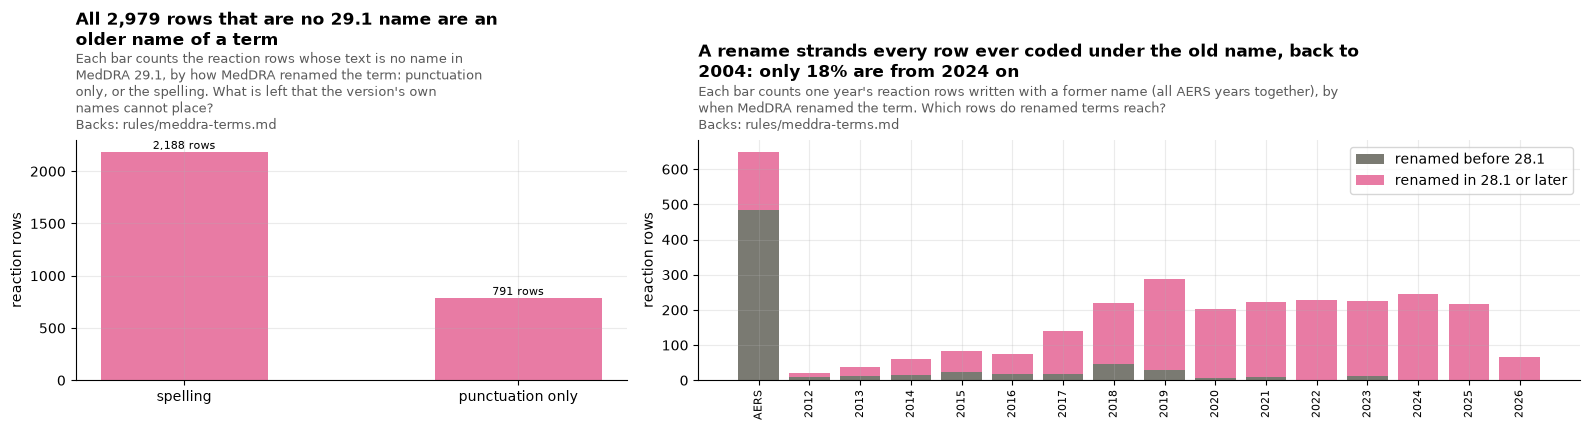

Former names: 44 terms on 2,979 rows and 2,957 cases of the case set (47 across every report version FDA published, which the build reads); 77.2% of the rows were renamed in 28.1 or later. The history file places every one; matching nothing: 0.


**What section 6 shows**, one item per chart:

- **What is left after the version's own names.** *Shows:* 44 terms (2,979 rows, 2,957 cases) are no name in 29.1; every one is a name MedDRA used before renaming the term: 13 differ only in punctuation (791 rows), 31 in spelling (2,188 rows). Nothing is outside MedDRA. *Point:* the history file, which comes in the same download, places every reaction. *So what:* the build reads it every time and stops if a reaction text matches nothing, which would mean the MedDRA file is older than the data (`rules/meddra-terms.md`).
- **Which rows renames reach.** *Shows:* 77% of these rows were renamed in 28.1 or later, but by the year they were coded they reach back to 2004: 650 AERS rows, and 18% from 2024 on. *Point:* a recent rename strands every older row written with the old name, and each new version adds more. *So what:* without the history file, these cases would get no current PT, no label flag and no SMQ.

In [15]:
ren = q("""
SELECT t.key_T, sum(r.n_rows) AS rows_, min(r.quarter_T) AS first_T, max(r.quarter_T) AS last_T,
       regexp_replace(t.key_T, '[^a-z0-9]', '', 'g') = regexp_replace(lower(l.name), '[^a-z0-9]', '', 'g') AS punctuation_only,
       (SELECT max(h.v) FROM own_hist h WHERE h.code = t.llt_code_T AND h.act = 'U') AS renamed_in
FROM rtext_T t JOIN rx_T r USING (text) JOIN own_llt l ON l.code = t.llt_code_T
WHERE t.class_T = 'former_name' GROUP BY ALL""")
ren_cases = one("""SELECT count(DISTINCT c.case_key_T) FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
                   JOIN rtext_T t ON t.text = r.pt WHERE t.class_T = 'former_name'""")[0]
kinds = (
    ren.groupby("punctuation_only")
    .agg(terms=("key_T", "nunique"), rows_=("rows_", "sum"))
    .rename(index={True: "punctuation only", False: "spelling"})
)
ry = (
    q("""SELECT CASE WHEN r.era_T = 'legacy' THEN 'AERS' ELSE substr(r.quarter_T, 1, 4) END AS year_T,
                 (SELECT max(h.v) FROM own_hist h WHERE h.code = r.llt_code_T AND h.act = 'U') >= 281 AS recent_T, sum(r.n_rows) AS n
          FROM rx_T r WHERE r.class_T = 'former_name' GROUP BY ALL""")
    .pivot_table(index="year_T", columns="recent_T", values="n", aggfunc="sum")
    .fillna(0)
)
ry = ry.reindex(["AERS"] + sorted(i for i in ry.index if i != "AERS"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
label_bars(
    a1, a1.bar(kinds.index, kinds.rows_, color=COLOR["former_name"], width=0.5), "{:,.0f} rows"
)
a1.set_ylabel("reaction rows")
title(
    a1,
    f"All {int(kinds.rows_.sum()):,} rows that are no {VERSION} name are an older name of a term",
    f"Each bar counts the reaction rows whose text is no name in MedDRA {VERSION}, by how MedDRA renamed the term: punctuation "
    "only, or the spelling.",
    "What is left that the version's own names cannot place?",
    "Backs: rules/meddra-terms.md",
)
bottom = np.zeros(len(ry))
for col, color, lbl in [
    (False, SERIES[6], "renamed before 28.1"),
    (True, COLOR["former_name"], "renamed in 28.1 or later"),
]:
    if col in ry:
        a2.bar(ry.index, ry[col], bottom=bottom, color=color, label=lbl)
        bottom += ry[col].values
a2.tick_params(axis="x", rotation=90, labelsize=8)
a2.set_ylabel("reaction rows")
a2.legend()
recent_share = 100 * ren.rows_[ren.renamed_in >= 281].sum() / ren.rows_.sum()
from_2024 = ry.loc[[i for i in ry.index if i >= "2024" and i != "AERS"]].values.sum()
title(
    a2,
    f"A rename strands every row ever coded under the old name, back to 2004: only {100 * from_2024 / ren.rows_.sum():.0f}% are from 2024 on",
    "Each bar counts one year's reaction rows written with a former name (all AERS years together), by when MedDRA renamed the term.",
    "Which rows do renamed terms reach?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
# second count: former names as this notebook reads the history file
ren2 = one("""SELECT count(DISTINCT own_key(r.text)), sum(r.n_rows) FROM rq_T r
              WHERE own_key(r.text) IN (SELECT k FROM own_name WHERE former)""")
assert ren2 == (len(ren), ren.rows_.sum())
on_all_versions = REPORT["columns"]["pt"]["former_names"]
print(
    f"Former names: {len(ren)} terms on {ren.rows_.sum():,.0f} rows and {ren_cases:,} cases of the case set ({on_all_versions} across every "
    f"report version FDA published, which the build reads); {recent_share:.1f}% of the rows were renamed in 28.1 or later. The history file "
    f"places every one; matching nothing: {REPORT['columns']['pt']['unmapped']['texts']}."
)
say(f"""
**What section 6 shows**, one item per chart:

- **What is left after the version's own names.** *Shows:* {len(ren)} terms ({ren.rows_.sum():,.0f} rows, {ren_cases:,} cases) are no name in {VERSION}; every one is a name MedDRA used before renaming the term: {kinds.loc["punctuation only", "terms"]} differ only in punctuation ({kinds.loc["punctuation only", "rows_"]:,.0f} rows), {kinds.loc["spelling", "terms"]} in spelling ({kinds.loc["spelling", "rows_"]:,.0f} rows). Nothing is outside MedDRA. *Point:* the history file, which comes in the same download, places every reaction. *So what:* the build reads it every time and stops if a reaction text matches nothing, which would mean the MedDRA file is older than the data (`rules/meddra-terms.md`).
- **Which rows renames reach.** *Shows:* {recent_share:.0f}% of these rows were renamed in 28.1 or later, but by the year they were coded they reach back to 2004: {ry.loc["AERS"].sum():,.0f} AERS rows, and {100 * from_2024 / ren.rows_.sum():.0f}% from 2024 on. *Point:* a recent rename strands every older row written with the old name, and each new version adds more. *So what:* without the history file, these cases would get no current PT, no label flag and no SMQ.
""")

## 7 · Indications and the reaction that came back on re-exposure

The same classes for the two other columns that hold MedDRA terms: `indi_pt` (what the drug was given for) and `drug_rec_act` (in FAERS since 2014, the reaction that came back when the drug was given again). Both are read by the same step as reactions.

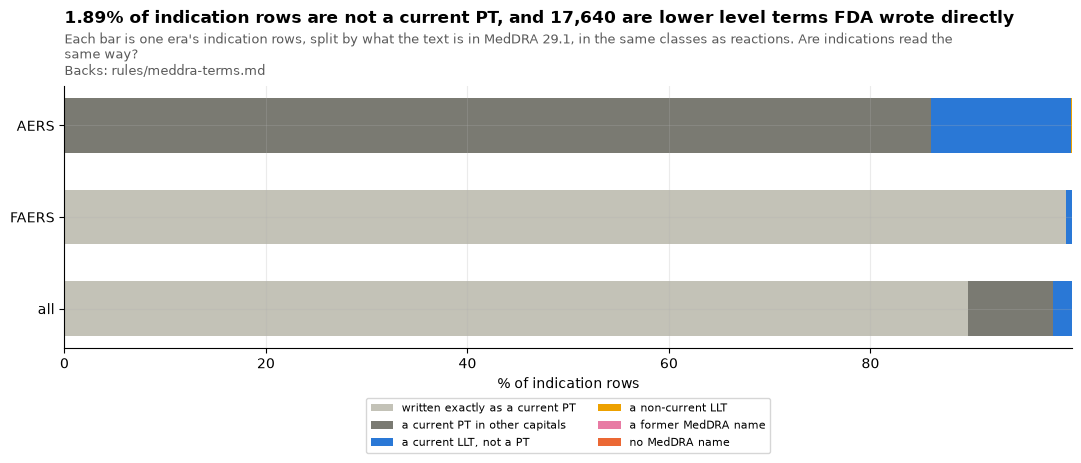

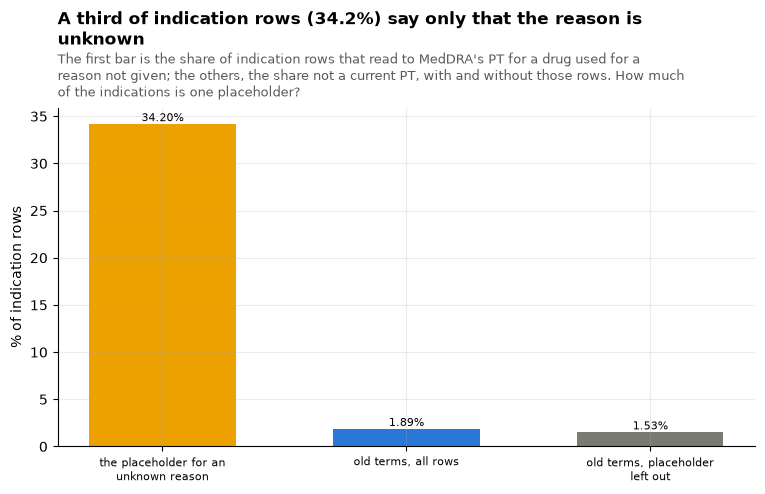

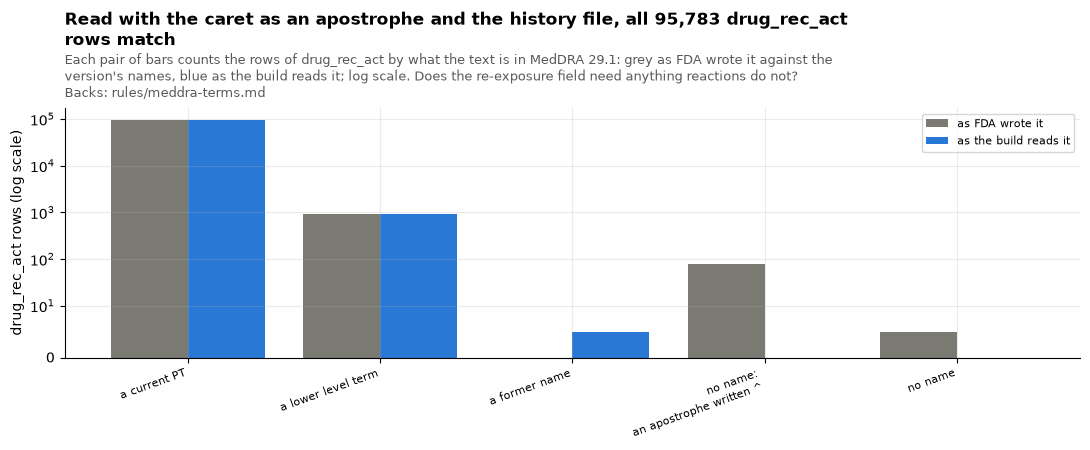

Indication rows: 49,127,336; not a current PT: 929,519 (1.89%), 1.53% without the placeholder; only capitals: 4,151,385; AERS written letter for letter as a PT: 0. Lower level terms that were never a PT: 17,640 rows. No MedDRA name, even with the history file: 74 texts on 105 rows. drug_rec_act: 95,783 rows on 45,932 cases; as written, 914 rows are lower level terms and 82 match no 29.1 name, 77 of them because of the caret; as the build reads it, none.


**What section 7 shows**, one item per chart:

- **Indications by what they are today.** *Shows:* of 49,127,336 indication rows, 929,519 (1.89%) are not a current PT and 4,151,385 differ only in capitals. Unlike reactions, part of the gap is coding, not age: 17,640 rows are lower level terms that were never a PT, which FDA wrote into the field directly. 74 texts (105 rows) are free text no MedDRA name covers, even with the history file. *Point:* the same reading works for indications, mechanically. *So what:* `indi_pt` is read by the same step as reactions; the 105 free-text rows stay as FDA wrote them, with no hand review, and the build reports them (`rules/meddra-terms.md`).
- **The placeholder.** *Shows:* 34.2% of all indication rows (16,800,102) read to MedDRA's PT for a drug used for a reason not given; its older wording is 47% of the old-term rows. Left out, the old-term share is 1.53% instead of 1.89%. *Point:* a third of what FAERS says drugs were given for says nothing. *So what:* a methods-page card says so; nothing in the data is changed.
- **The re-exposure reaction.** *Shows:* `drug_rec_act` holds 95,783 rows on 45,932 cases; as FDA wrote them, 914 rows are lower level terms and 82 match no 29.1 name, 77 of them because FDA writes the apostrophe as `^` there and nowhere else. Read with the caret as an apostrophe and with the history file, every row matches. *Point:* the third MedDRA column needs one fix of its own. *So what:* the step reads `^` as an apostrophe in `drug_rec_act` (`apostrophe_as_caret` in `rules/meddra-terms.md`); FDA's text is not changed.

In [16]:
con.execute(f"""CREATE TABLE ix_T AS
WITH t AS (SELECT d.text, m.indi_term_T AS key_T, {CLASS_SQL} AS class_T, m.pt_code_T, m.llt_code_T
           FROM (SELECT DISTINCT indi_pt AS text FROM indi_latest_T WHERE indi_pt IS NOT NULL) d
           LEFT JOIN indi_meddra_T m ON m.indi_term_T = {key("indi_pt", "d.text")} LEFT JOIN meddra_pt p ON p.pt_name = d.text)
SELECT i.era_T, i.quarter_T, t.*, count(*) AS n_rows FROM indi_latest_T i JOIN t ON t.text = i.indi_pt GROUP BY ALL""")
ir = (
    q("SELECT era_T, class_T, sum(n_rows) AS n FROM ix_T GROUP BY ALL")
    .pivot_table(index="era_T", columns="class_T", values="n", aggfunc="sum")
    .reindex(columns=CLASSES)
    .fillna(0)
)
ir.loc["all"] = ir.sum()
i_total, i_old = ir.loc["all"].sum(), ir.loc["all", list(OLD)].sum()
# MedDRA's PT for a drug used for a reason not given: the PT the most indication rows reach
placeholder = q(
    "SELECT pt_code_T, sum(n_rows) AS n FROM ix_T WHERE pt_code_T IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 1"
).iloc[0]
ph_rows = placeholder.n
ph_old = one(
    f"SELECT sum(n_rows) FROM ix_T WHERE pt_code_T = '{placeholder.pt_code_T}' AND class_T IN {OLD}"
)[0]
never = one(
    "SELECT sum(n_rows) FROM ix_T WHERE class_T IN ('llt_current', 'llt_noncurrent') AND llt_code_T NOT IN "
    "(SELECT code FROM own_hist WHERE lvl = 'PT' AND act = 'A')"
)[0]
free = one("SELECT count(DISTINCT key_T), sum(n_rows) FROM ix_T WHERE class_T = 'none'")
# drug_rec_act: as FDA wrote it against the version's names, and as the build reads it (the caret, the history file)
dra = q(
    """SELECT r.drug_rec_act AS text, count(*) AS n FROM reac_latest_T r WHERE r.drug_rec_act IS NOT NULL GROUP BY 1"""
)
dra_cases = one("""SELECT count(DISTINCT c.case_key_T) FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
                   WHERE r.drug_rec_act IS NOT NULL""")[0]
con.register("dra_df", dra)
as_written = (
    q("""SELECT CASE WHEN own_key(d.text) IN (SELECT own_key(name) FROM own_pt) THEN 'a current PT'
                              WHEN own_key(d.text) IN (SELECT k FROM own_name WHERE NOT former) THEN 'a lower level term'
                              WHEN contains(d.text, '^') THEN 'no name: an apostrophe written ^'
                              ELSE 'no name' END AS kind_T, sum(n) AS n FROM dra_df d GROUP BY 1""")
    .set_index("kind_T")
    .n.astype(int)
)
as_read = (
    q(f"""SELECT CASE WHEN m.pt_current_T THEN 'a current PT' WHEN m.matched_as_T = 'llt' THEN 'a lower level term'
                           WHEN m.matched_as_T = 'former_name' THEN 'a former name' ELSE 'no name' END AS kind_T, sum(d.n) AS n
                FROM dra_df d LEFT JOIN drug_rec_act_meddra_T m ON m.drug_rec_act_term_T = {key("drug_rec_act", "d.text")} GROUP BY 1""")
    .set_index("kind_T")
    .n.astype(int)
)
fig, a1 = plt.subplots(figsize=(13, 3.4))
order = ["legacy", "faers", "all"]
left = np.zeros(3)
data = 100 * ir.div(ir.sum(axis=1), axis=0)
for c in [c for c in CLASSES if data[c].sum() > 0]:
    v = data.loc[order, c].values
    a1.barh(
        ["AERS", "FAERS", "all"][::-1],
        v[::-1],
        left=left[::-1],
        color=COLOR[c],
        label=LABEL[c],
        height=0.6,
    )
    left += v
a1.set_xlabel("% of indication rows")
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8)
title(
    a1,
    f"{100 * i_old / i_total:.2f}% of indication rows are not a current PT, and {never:,} are lower level terms FDA wrote directly",
    f"Each bar is one era's indication rows, split by what the text is in MedDRA {VERSION}, in the same classes as reactions.",
    "Are indications read the same way?",
    "Backs: rules/meddra-terms.md",
)
plt.show()
fig, a2 = plt.subplots(figsize=(9, 4.4))
parts = pd.Series(
    {
        "the placeholder for an\nunknown reason": 100 * ph_rows / i_total,
        "old terms, all rows": 100 * i_old / i_total,
        "old terms, placeholder\nleft out": 100 * (i_old - ph_old) / (i_total - ph_rows),
    }
)
label_bars(
    a2,
    a2.bar(parts.index, parts.values, color=[SERIES[3], SERIES[0], SERIES[6]], width=0.6),
    "{:.2f}%",
)
a2.set_ylabel("% of indication rows")
a2.tick_params(axis="x", labelsize=8)
title(
    a2,
    f"A third of indication rows ({100 * ph_rows / i_total:.1f}%) say only that the reason is unknown",
    "The first bar is the share of indication rows that read to MedDRA's PT for a drug used for a reason not given; the others, "
    "the share not a current PT, with and without those rows.",
    "How much of the indications is one placeholder?",
)
plt.show()
fig, a3 = plt.subplots(figsize=(11, 4.6))
kinds_ = [
    "a current PT",
    "a lower level term",
    "a former name",
    "no name: an apostrophe written ^",
    "no name",
]
xw = np.arange(len(kinds_))
a3.bar(
    xw - 0.2, [as_written.get(k, 0) for k in kinds_], 0.4, color=SERIES[6], label="as FDA wrote it"
)
a3.bar(
    xw + 0.2,
    [as_read.get(k, 0) for k in kinds_],
    0.4,
    color=SERIES[0],
    label="as the build reads it",
)
a3.set_yscale("symlog", linthresh=10)
a3.set_xticks(xw)
a3.set_xticklabels([k.replace(": ", ":\n") for k in kinds_], fontsize=8, rotation=20, ha="right")
a3.set_ylabel("drug_rec_act rows (log scale)")
a3.legend(fontsize=8)
title(
    a3,
    f"Read with the caret as an apostrophe and the history file, all {dra.n.sum():,} drug_rec_act rows match",
    f"Each pair of bars counts the rows of drug_rec_act by what the text is in MedDRA {VERSION}: grey as FDA wrote it against the "
    "version's names, blue as the build reads it; log scale.",
    "Does the re-exposure field need anything reactions do not?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
# second counts, written apart
i2 = one(
    "SELECT count(*) FROM indi_latest_T WHERE indi_pt IS NOT NULL AND own_key(indi_pt) NOT IN (SELECT own_key(name) FROM own_pt)"
)[0]
assert i2 == i_old
assert (free[0], free[1]) == (
    REPORT["columns"]["indi_pt"]["unmapped"]["texts"],
    REPORT["columns"]["indi_pt"]["unmapped"]["rows"],
)
assert as_read.get("no name", 0) == 0 == REPORT["columns"]["drug_rec_act"]["unmapped"]["texts"]
print(
    f"Indication rows: {i_total:,.0f}; not a current PT: {i_old:,.0f} ({100 * i_old / i_total:.2f}%), {100 * (i_old - ph_old) / (i_total - ph_rows):.2f}% "
    f"without the placeholder; only capitals: {ir.loc['all', 'pt_case']:,.0f}; AERS written letter for letter as a PT: {ir.loc['legacy', 'pt_exact']:,.0f}. "
    f"Lower level terms that were never a PT: {never:,} rows. No MedDRA name, even with the history file: {free[0]} texts on {free[1]} rows. "
    f"drug_rec_act: {dra.n.sum():,} rows on {dra_cases:,} cases; as written, {as_written.get('a lower level term', 0):,} rows are lower level terms and "
    f"{as_written.get('no name: an apostrophe written ^', 0) + as_written.get('no name', 0):,} match no {VERSION} name, "
    f"{as_written.get('no name: an apostrophe written ^', 0)} of them because of the caret; as the build reads it, none."
)
say(f"""
**What section 7 shows**, one item per chart:

- **Indications by what they are today.** *Shows:* of {i_total:,.0f} indication rows, {i_old:,.0f} ({100 * i_old / i_total:.2f}%) are not a current PT and {ir.loc["all", "pt_case"]:,.0f} differ only in capitals. Unlike reactions, part of the gap is coding, not age: {never:,} rows are lower level terms that were never a PT, which FDA wrote into the field directly. {free[0]} texts ({free[1]} rows) are free text no MedDRA name covers, even with the history file. *Point:* the same reading works for indications, mechanically. *So what:* `indi_pt` is read by the same step as reactions; the {free[1]} free-text rows stay as FDA wrote them, with no hand review, and the build reports them (`rules/meddra-terms.md`).
- **The placeholder.** *Shows:* {100 * ph_rows / i_total:.1f}% of all indication rows ({ph_rows:,.0f}) read to MedDRA's PT for a drug used for a reason not given; its older wording is {100 * ph_old / i_old:.0f}% of the old-term rows. Left out, the old-term share is {100 * (i_old - ph_old) / (i_total - ph_rows):.2f}% instead of {100 * i_old / i_total:.2f}%. *Point:* a third of what FAERS says drugs were given for says nothing. *So what:* a methods-page card says so; nothing in the data is changed.
- **The re-exposure reaction.** *Shows:* `drug_rec_act` holds {dra.n.sum():,} rows on {dra_cases:,} cases; as FDA wrote them, {as_written.get("a lower level term", 0):,} rows are lower level terms and {as_written.get("no name: an apostrophe written ^", 0) + as_written.get("no name", 0):,} match no {VERSION} name, {as_written.get("no name: an apostrophe written ^", 0)} of them because FDA writes the apostrophe as `^` there and nowhere else. Read with the caret as an apostrophe and with the history file, every row matches. *Point:* the third MedDRA column needs one fix of its own. *So what:* the step reads `^` as an apostrophe in `drug_rec_act` (`apostrophe_as_caret` in `rules/meddra-terms.md`); FDA's text is not changed.
""")

## 8 · The build's mapping, checked

The sections above count through the build's own tables. Here those tables are compared, term by term, with this notebook's own reading of MedDRA's files (its own parser, its own key, former names from the history file as it reads them): the PT each gives every distinct reaction term, and whether each calls it a current PT. Agreement shows the build's code does what this notebook does by other means; both rest on MedDRA's files.

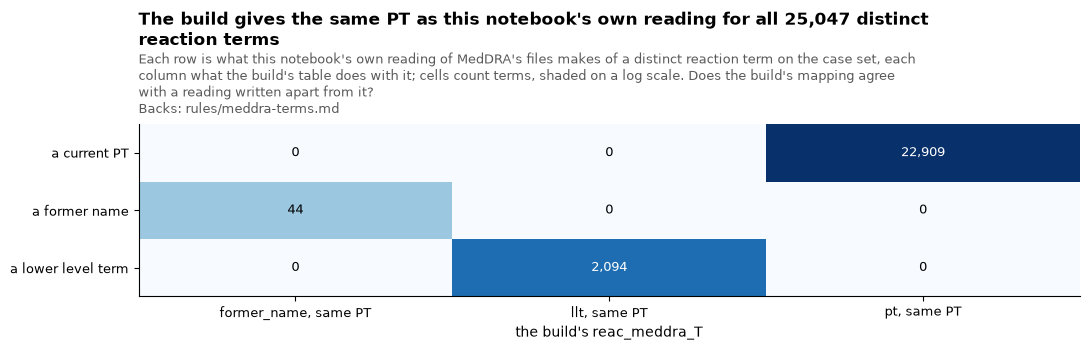

The build maps all 25,047 distinct terms of the case set to the PT this notebook's own reading gives (25,003 by the 29.1 names, 44 through the history file), and calls the same ones current PTs.


**What section 8 shows**, one item per chart:

- **The build against this notebook's own reading.** *Shows:* for all 25,047 distinct reaction terms of the case set, the build's `reac_meddra_T` gives the PT this notebook's own parser and key give, disagrees on none, and flags the same terms as current PTs; the 44 former names are placed through the history file by both. Sections 2 and 7 check the build's report the same way: the quarters that fit no single version, and the indication and `drug_rec_act` texts that match nothing. *Point:* the build's code does what MedDRA's files say, read twice. It is a check of the code, not an independent check of MedDRA, which both read. *So what:* the licensed part can be trusted to carry the mapping the methods page describes.

In [17]:
cmp_ = q("""
WITH mine AS (SELECT t.key_T, any_value(n.pt) AS pt, bool_or(coalesce(n.is_pt, FALSE)) AS is_pt, bool_or(n.former) AS former
              FROM rtext_T t JOIN own_name n ON n.k = own_key(t.text) GROUP BY 1)
SELECT CASE WHEN m.former THEN 'a former name' WHEN m.is_pt THEN 'a current PT' ELSE 'a lower level term' END AS mine_T,
       coalesce(b.matched_as_T, 'no match') || CASE WHEN b.pt_code_T = m.pt THEN ', same PT' WHEN b.pt_code_T IS NULL THEN '' ELSE ', another PT' END AS build_T,
       count(*) AS terms, count(*) FILTER (WHERE b.pt_current_T <> m.is_pt) AS flag_differs
FROM mine m JOIN reac_meddra_T b ON b.reac_term_T = m.key_T GROUP BY ALL""")
ct = cmp_.pivot_table(index="mine_T", columns="build_T", values="terms", aggfunc="sum").fillna(0)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(np.log10(ct.values + 1), cmap="Blues", aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(ct.columns)))
ax.set_xticklabels(ct.columns, fontsize=9)
ax.set_yticks(range(len(ct.index)))
ax.set_yticklabels(ct.index, fontsize=9)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(
            j,
            i,
            f"{int(ct.values[i, j]):,}",
            ha="center",
            va="center",
            fontsize=9,
            color="#000" if ct.values[i, j] < 2000 else "#fff",
        )
ax.set_xlabel("the build's reac_meddra_T")
agree = int(cmp_[cmp_.build_T.str.endswith("same PT")].terms.sum())
title(
    ax,
    f"The build gives the same PT as this notebook's own reading for all {agree:,} distinct reaction terms",
    "Each row is what this notebook's own reading of MedDRA's files makes of a distinct reaction term on the case set, each column "
    "what the build's table does with it; cells count terms, shaded on a log scale.",
    "Does the build's mapping agree with a reading written apart from it?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
assert (
    agree == terms[0]
    and cmp_.flag_differs.sum() == 0
    and not cmp_.build_T.str.contains("another|no match").any()
)
print(
    f"The build maps all {agree:,} distinct terms of the case set to the PT this notebook's own reading gives "
    f"({agree - terms[1]:,} by the {VERSION} names, {terms[1]} through the history file), and calls the same ones current PTs."
)
say(f"""
**What section 8 shows**, one item per chart:

- **The build against this notebook's own reading.** *Shows:* for all {agree:,} distinct reaction terms of the case set, the build's `reac_meddra_T` gives the PT this notebook's own parser and key give, disagrees on none, and flags the same terms as current PTs; the {terms[1]} former names are placed through the history file by both. Sections 2 and 7 check the build's report the same way: the quarters that fit no single version, and the indication and `drug_rec_act` texts that match nothing. *Point:* the build's code does what MedDRA's files say, read twice. It is a check of the code, not an independent check of MedDRA, which both read. *So what:* the licensed part can be trusted to carry the mapping the methods page describes.
""")

## 9 · What counting under current PTs changes for statistics

The statistics (disproportionality, such as PRR and EBGM) count pairs of a product and a reaction. Counted on FDA's text, an old term and its current PT are two reactions; read to current PTs they are one. The case set here is the statistics' own: the kept FAERS cases naming a suspect (PS or SS) ingredient in FDA's `prod_ai`. A pair counts its cases once.

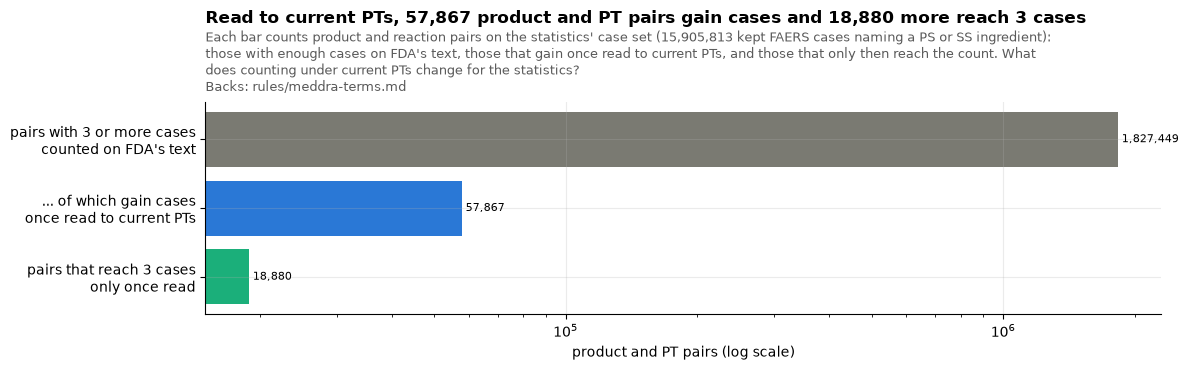

15,905,813 cases; pairs with 3+ cases on FDA's text 1,827,449, read to current PTs 1,846,329; 57,867 gain, 18,880 reach 3 only once read. For levetiracetam, its largest pair that gains: 'Seizure', 10,145 to 10,353 cases.


**What section 9 shows**, one item per chart:

- **The statistics' pairs.** *Shows:* on the statistics' case set (15,905,813 kept FAERS cases naming a PS or SS ingredient), 1,827,449 product and PT pairs have 3 or more cases counted on FDA's text. Read to current PTs, 57,867 pairs with 3 or more cases gain cases, and 18,880 reach 3 cases only then. For a newer drug the gain is small: levetiracetam's largest such pair goes from 10,145 to 10,353 cases. *Point:* on FDA's text, an old term and its current PT are two reactions in every statistic, and the newest version's demotions split pairs further. *So what:* the statistics count each reaction under its current PT, named by PT names, as label flags and search do (`rules/meddra-terms.md`).

In [18]:
con.execute("""CREATE TABLE sp_T AS SELECT DISTINCT c.case_key_T, d.prod_ai_norm_T AS product_T
  FROM drug_latest_T d JOIN case_latest_T c USING (era_T, primaryid, quarter_T)
  WHERE c.dup_kept_T AND c.era_T = 'faers' AND d.role_cod IN ('PS', 'SS') AND d.prod_ai_norm_T IS NOT NULL""")
con.execute("""CREATE TABLE pairs_T AS
WITH e AS (SELECT c.case_key_T, t.pt_code_T, bool_or(t.class_T IN ('pt_exact', 'pt_case')) AS direct_T
           FROM reac_latest_T r JOIN case_latest_T c USING (era_T, primaryid, quarter_T) JOIN rtext_T t ON t.text = r.pt
           WHERE c.case_key_T IN (SELECT case_key_T FROM sp_T) GROUP BY ALL)
SELECT s.product_T, e.pt_code_T, count(*) AS mapped_T, count(*) FILTER (WHERE e.direct_T) AS text_T
FROM sp_T s JOIN e USING (case_key_T) GROUP BY ALL""")
MIN_CASES = 3  # the smallest count the statistics report a pair at
stat_cases = one("SELECT count(DISTINCT case_key_T) FROM sp_T")[0]
st = one(f"""SELECT count(*) FILTER (WHERE text_T >= {MIN_CASES}), count(*) FILTER (WHERE mapped_T >= {MIN_CASES} AND mapped_T > text_T),
  count(*) FILTER (WHERE mapped_T >= {MIN_CASES} AND text_T < {MIN_CASES}), count(*) FILTER (WHERE mapped_T >= {MIN_CASES})
  FROM pairs_T""")
drug = "LEVETIRACETAM"  # a newer antiepileptic: most of its reports are recent
example_pair = q(f"""SELECT p.pt_name, x.text_T, x.mapped_T FROM pairs_T x JOIN meddra_pt p ON p.pt_code = x.pt_code_T
                     WHERE x.product_T = '{drug}' AND x.mapped_T > x.text_T ORDER BY x.mapped_T DESC LIMIT 1""").iloc[
    0
]
fig, ax = plt.subplots(figsize=(12, 3.8))
bars_ = pd.Series(
    {
        f"pairs with {MIN_CASES} or more cases\ncounted on FDA's text": st[0],
        "... of which gain cases\nonce read to current PTs": st[1],
        f"pairs that reach {MIN_CASES} cases\nonly once read": st[2],
    }
)
label_bars(
    ax,
    ax.barh(bars_.index[::-1], bars_.values[::-1], color=[SERIES[2], SERIES[0], SERIES[6]]),
    horizontal=True,
)
ax.set_xscale("log")
ax.set_xlabel("product and PT pairs (log scale)")
title(
    ax,
    f"Read to current PTs, {st[1]:,} product and PT pairs gain cases and {st[2]:,} more reach {MIN_CASES} cases",
    f"Each bar counts product and reaction pairs on the statistics' case set ({stat_cases:,} kept FAERS cases naming a PS or SS "
    "ingredient): those with enough cases on FDA's text, those that gain once read to current PTs, and those that only then reach the count.",
    "What does counting under current PTs change for the statistics?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()
# second count, written apart: the same pairs through this notebook's own names
st2 = one(f"""
WITH e AS (SELECT c.case_key_T, n.pt, bool_or(coalesce(n.is_pt, FALSE)) AS direct FROM reac_latest_T r
           JOIN case_latest_T c USING (era_T, primaryid, quarter_T) JOIN own_name n ON n.k = own_key(r.pt)
           WHERE c.case_key_T IN (SELECT case_key_T FROM sp_T) GROUP BY ALL),
p AS (SELECT s.product_T, e.pt, count(*) AS m, count(*) FILTER (WHERE direct) AS t FROM sp_T s JOIN e USING (case_key_T) GROUP BY ALL)
SELECT count(*) FILTER (WHERE t >= {MIN_CASES}), count(*) FILTER (WHERE m >= {MIN_CASES} AND m > t),
       count(*) FILTER (WHERE m >= {MIN_CASES} AND t < {MIN_CASES}), count(*) FILTER (WHERE m >= {MIN_CASES}) FROM p""")
assert st2 == st
print(
    f"{stat_cases:,} cases; pairs with {MIN_CASES}+ cases on FDA's text {st[0]:,}, read to current PTs {st[3]:,}; {st[1]:,} gain, {st[2]:,} reach "
    f"{MIN_CASES} only once read. For {drug.lower()}, its largest pair that gains: {example_pair.pt_name!r}, {example_pair.text_T:,} to {example_pair.mapped_T:,} cases."
)
say(f"""
**What section 9 shows**, one item per chart:

- **The statistics' pairs.** *Shows:* on the statistics' case set ({stat_cases:,} kept FAERS cases naming a PS or SS ingredient), {st[0]:,} product and PT pairs have {MIN_CASES} or more cases counted on FDA's text. Read to current PTs, {st[1]:,} pairs with {MIN_CASES} or more cases gain cases, and {st[2]:,} reach {MIN_CASES} cases only then. For a newer drug the gain is small: {drug.lower()}'s largest such pair goes from {example_pair.text_T:,} to {example_pair.mapped_T:,} cases. *Point:* on FDA's text, an old term and its current PT are two reactions in every statistic, and the newest version's demotions split pairs further. *So what:* the statistics count each reaction under its current PT, named by PT names, as label flags and search do (`rules/meddra-terms.md`).
""")

## Methods-page cards from this notebook

The cards this notebook backs, computed by the same functions the release build calls when it is built with MedDRA (`src/open_altio/faers/insights/cards/meddra.py`), on the release and the MedDRA version this notebook reads: older terms a search on today's term misses (rule `meddra-terms`), quarterly files that keep their MedDRA version (rule `meddra-version`), and the placeholder that fills a third of the indications (documented, nothing changed). They show counts and PT names only. Each is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT/cards/`).

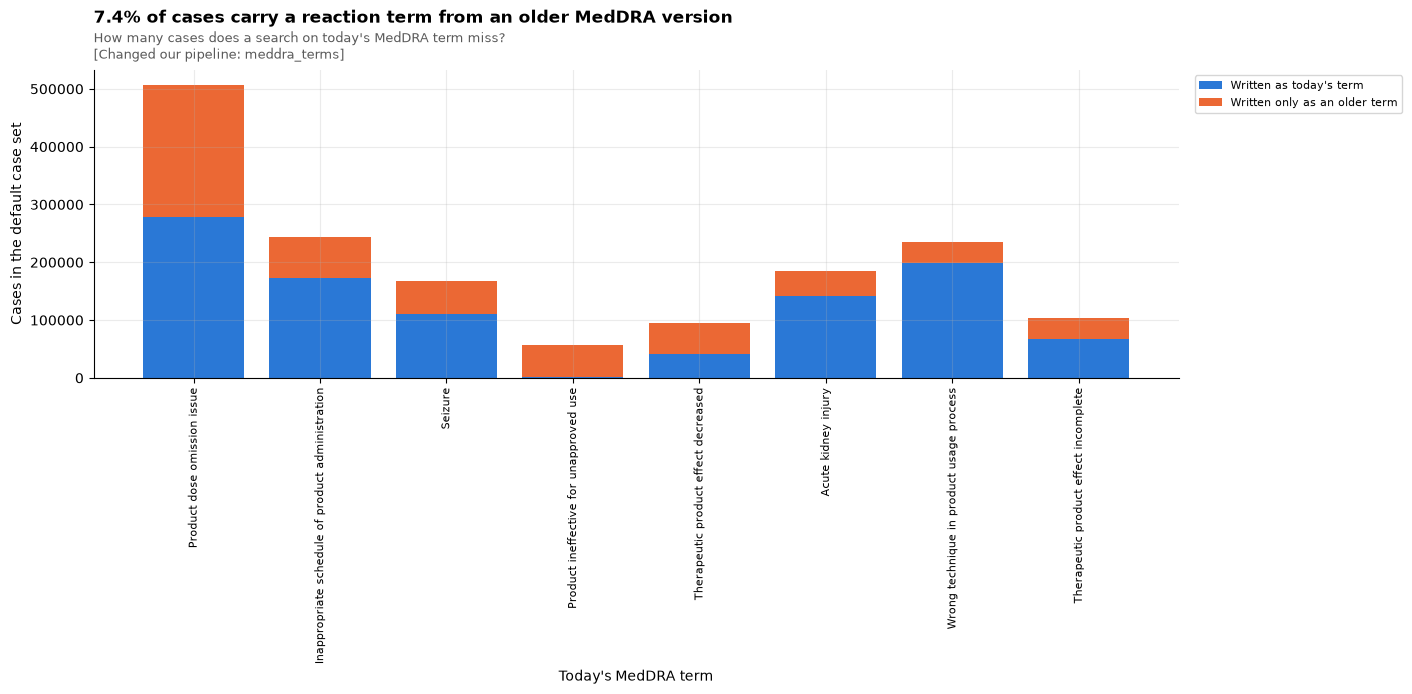

FDA codes each report in the MedDRA version of its day, and MedDRA later demotes or renames terms, so 1,492,555 cases (18.9% of AERS cases, 5.4% of FAERS cases) carry a reaction that is not a current term. A search on today's term misses 1,483,990 of them: Product dose omission issue alone is written another way in 229,776 cases.


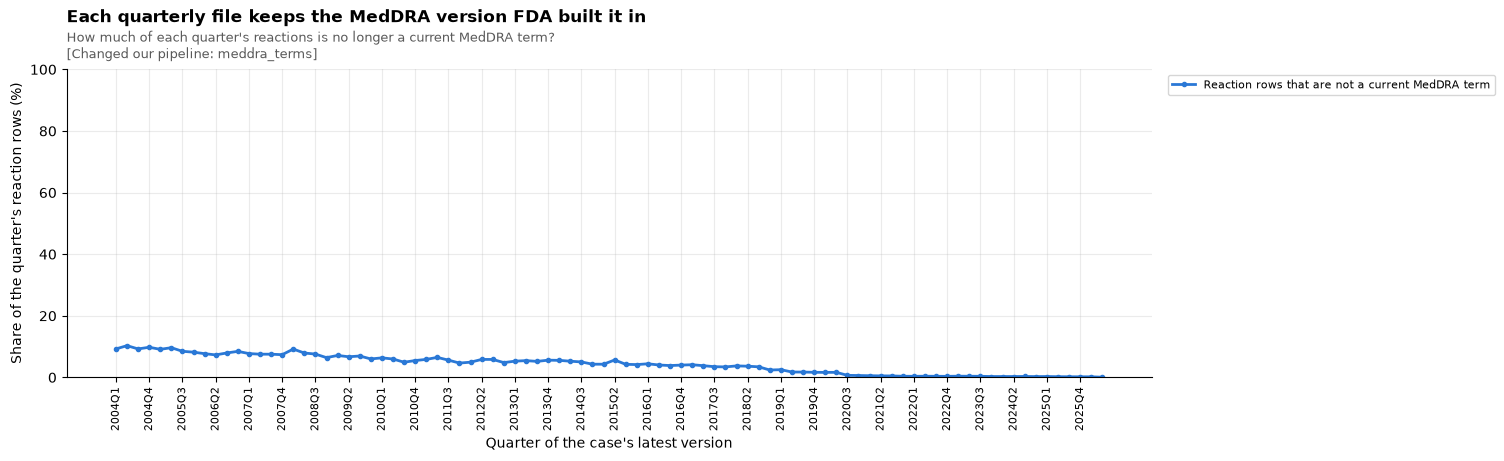

FDA recodes its own database to each new MedDRA version but never reissues a published file, so the older the quarter, the more of its terms are no longer current: up to 10.3% of an AERS quarter's rows (2004Q2) and 5.6% of a FAERS quarter's (2015Q2), against 0.06% in 2026Q2. This release reads every quarter in one version, MedDRA 29.1, the newest when it was built.


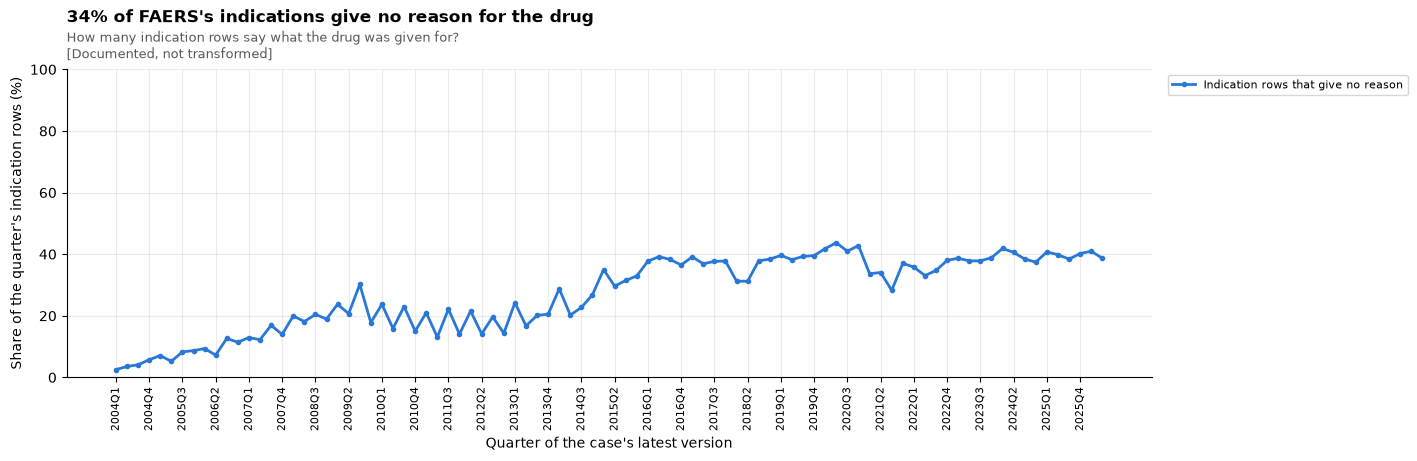

16,521,152 of 48,245,058 indication rows are MedDRA's term for a drug used for a reason not given (Product used for unknown indication), in today's wording or an older one. A count or filter of what drugs were given for leaves these rows out, or counts them as one indication.
notebooks/out/cards/06_meddra_versions.json


In [19]:
cards = compute_cards(
    con,
    [
        "older_meddra_terms_missed",
        "quarterly_files_keep_their_meddra_version",
        "unknown_indication_placeholder",
    ],
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "06_meddra_versions"))
missed_card = next(c for c in cards if c["id"] == "older_meddra_terms_missed")
assert (
    f"misses {cases.loc['all', 'missed_default']:,} of them" in missed_card["two_sentences"]
)  # the default view, as counted in section 3

## The choices made

Each choice with its numbers on this release and what it changed in the code. The chart shows the reaction cases left outside their current PT at each stage: FDA's text alone, the version's own names, and the history file too.

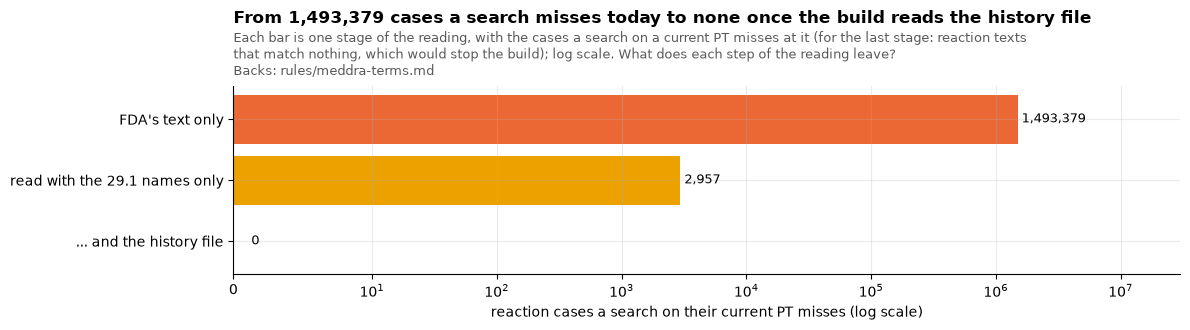

In [20]:
left_ = pd.Series(
    {
        "FDA's text only": cases.loc["all", "missed"],
        f"read with the {VERSION} names only": ren_cases,
        "... and the history file": REPORT["columns"]["pt"]["unmapped"]["texts"],
    }
)
fig, ax = plt.subplots(figsize=(12, 3.4))
bars = ax.barh(left_.index[::-1], left_.values[::-1], color=[SERIES[2], SERIES[3], SERIES[1]])
for b, v in zip(bars, left_.values[::-1], strict=True):
    ax.text(
        max(b.get_width(), 1), b.get_y() + b.get_height() / 2, f" {v:,}", va="center", fontsize=9
    )
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, left_.max() * 20)
ax.set_xlabel("reaction cases a search on their current PT misses (log scale)")
title(
    ax,
    f"From {left_.iloc[0]:,} cases a search misses today to none once the build reads the history file",
    "Each bar is one stage of the reading, with the cases a search on a current PT misses at it (for the last stage: reaction texts "
    "that match nothing, which would stop the build); log scale.",
    "What does each step of the reading leave?",
    "Backs: rules/meddra-terms.md",
)
plt.tight_layout()
plt.show()

In [21]:
added = q("SELECT code, min(v) AS v FROM own_hist WHERE lvl = 'LLT' AND act = 'A' GROUP BY 1")
last_q = quarters[-1]
prev = versions[versions.index(coded[last_q]) - 1]
newer_codes = set(added[added.v > int(prev.replace(".", ""))].code)
older_file_rows = int(
    rows_by_code[(rows_by_code.quarter_T == last_q) & rows_by_code.code.isin(newer_codes)].n.sum()
)
say(f"""
1. **One MedDRA version per release, the newest at build time** (`rules/meddra-version.md`). Every quarter is within one version of its time and {(fits.str.len() == 1).sum()} of {len(fits)} fit exactly one; {last_q.upper()} is coded in {coded[last_q]}, and a {prev} file would leave {older_file_rows:,} of its reaction rows matching nothing. Each release is built with the newest MedDRA version out when it is built, and everything in it uses that one version: the mapping, and later the label dictionary and flags, the statistics and SMQs. A new version is taken up just before the next data build, never partway through a release. *In the code:* a release build given a MedDRA folder reads FDA's terms to it in its own database and writes the licensed part with the release (`build_release(..., meddra_dir=...)`); a reaction text that matches nothing refuses the file as older than the data, so one check does both jobs (`open_altio.faers.meddra.map_licensed`).
2. **Reactions are counted under their current PT** (`rules/meddra-terms.md`). Today a search on a current PT misses {cases.loc["all", "missed"]:,} cases ({cases.loc["all", "missed_default"]:,} in the default view), and {st[1]:,} of the statistics' product and PT pairs gain cases once read. Statistics, label flags, charts and reaction search count current PTs for everyone, named by PT names; the case list shows FDA's text as written; downloads carry FDA's text only, and the text to PT mapping stays in the licensed part (`licensed/meddra/`). People who hold MedDRA, and local copies run with their own MedDRA file, also see the current PT beside FDA's text, search by lower level term, and use codes, the hierarchy and SMQs. When MedDRA later split a term, older reports stay under the term they were coded in ({took_cases:,} cases in the largest re-promotion here, {100 * took_cases / in_smq:.1f}% of the cases under its SMQ's PTs); the methods page says so. *In the code:* the licensed tables `reac_meddra_T`, `drug_rec_act_meddra_T` and `indi_meddra_T` (`open_altio.faers.meddra.terms`) give every distinct text its current PT, for the explorer and the statistics to read.
3. **MedDRA's history file is read at every build** (`rules/meddra-terms.md`). It places the {len(ren)} renamed reaction terms ({ren.rows_.sum():,.0f} rows, {ren_cases:,} cases) through their codes. The build stops if any reaction text matches nothing ({REPORT["columns"]["pt"]["unmapped"]["texts"]} today); for indications and `drug_rec_act` it reports how many match nothing ({free[0]} indication texts on {free[1]} rows, left as FDA wrote them; {REPORT["columns"]["drug_rec_act"]["unmapped"]["texts"]} in `drug_rec_act`), and it reports the quarters that fit no single version ({", ".join(f"{qq.upper()}, by {n} rows" for qq, (_v, n) in mine_off.items()) or "none"}). *In the code:* `meddra_history_english.asc` is one of the files the step reads and keeps, and former names are the last match in `meddra_term_T`.
4. **`indi_pt` and `drug_rec_act` are read by the same step as `pt`** (`rules/meddra-terms.md`). {i_old:,.0f} indication rows ({100 * i_old / i_total:.2f}%) are not a current PT; `drug_rec_act` writes the apostrophe as `^` on {as_written.get("no name: an apostrophe written ^", 0)} rows, read as an apostrophe before matching. FDA's text is never changed. *In the code:* one SQL template writes all three mapping tables, and one test checks all three.
5. **Legacy terms are shown in MedDRA's spelling, taken from FAERS's own text** (`rules/legacy-term-spelling.md`). FAERS spells the same term for {100 * outcome.iloc[:2].sum() / outcome.sum():.1f}% of AERS reaction rows; where it spells a term two ways ({len(twice)} terms), the more common spelling; terms it never spells stay as written. Indications are treated the same way ({100 * indi_spelled:.1f}% of AERS indication rows). FDA's `pt` and `indi_pt` stay as written, beside the spelling. *In the code:* the public columns `pt_spelling_T` on `reac_latest_T` and `indi_pt_spelling_T` on `indi_latest_T` (`open_altio.faers.spelling`), carried into the explorer's database. No case is kept or set aside differently.
""")
con.close()
DB.unlink()  # nothing of MedDRA's stays on disk

1. **One MedDRA version per release, the newest at build time** (`rules/meddra-version.md`). Every quarter is within one version of its time and 89 of 90 fit exactly one; 2026Q2 is coded in 29.0, and a 28.1 file would leave 5,994 of its reaction rows matching nothing. Each release is built with the newest MedDRA version out when it is built, and everything in it uses that one version: the mapping, and later the label dictionary and flags, the statistics and SMQs. A new version is taken up just before the next data build, never partway through a release. *In the code:* a release build given a MedDRA folder reads FDA's terms to it in its own database and writes the licensed part with the release (`build_release(..., meddra_dir=...)`); a reaction text that matches nothing refuses the file as older than the data, so one check does both jobs (`open_altio.faers.meddra.map_licensed`).
2. **Reactions are counted under their current PT** (`rules/meddra-terms.md`). Today a search on a current PT misses 1,493,379 cases (1,483,990 in the default view), and 57,867 of the statistics' product and PT pairs gain cases once read. Statistics, label flags, charts and reaction search count current PTs for everyone, named by PT names; the case list shows FDA's text as written; downloads carry FDA's text only, and the text to PT mapping stays in the licensed part (`licensed/meddra/`). People who hold MedDRA, and local copies run with their own MedDRA file, also see the current PT beside FDA's text, search by lower level term, and use codes, the hierarchy and SMQs. When MedDRA later split a term, older reports stay under the term they were coded in (1,545 cases in the largest re-promotion here, 0.6% of the cases under its SMQ's PTs); the methods page says so. *In the code:* the licensed tables `reac_meddra_T`, `drug_rec_act_meddra_T` and `indi_meddra_T` (`open_altio.faers.meddra.terms`) give every distinct text its current PT, for the explorer and the statistics to read.
3. **MedDRA's history file is read at every build** (`rules/meddra-terms.md`). It places the 44 renamed reaction terms (2,979 rows, 2,957 cases) through their codes. The build stops if any reaction text matches nothing (0 today); for indications and `drug_rec_act` it reports how many match nothing (74 indication texts on 105 rows, left as FDA wrote them; 0 in `drug_rec_act`), and it reports the quarters that fit no single version (2017Q1, by 2 rows). *In the code:* `meddra_history_english.asc` is one of the files the step reads and keeps, and former names are the last match in `meddra_term_T`.
4. **`indi_pt` and `drug_rec_act` are read by the same step as `pt`** (`rules/meddra-terms.md`). 929,519 indication rows (1.89%) are not a current PT; `drug_rec_act` writes the apostrophe as `^` on 77 rows, read as an apostrophe before matching. FDA's text is never changed. *In the code:* one SQL template writes all three mapping tables, and one test checks all three.
5. **Legacy terms are shown in MedDRA's spelling, taken from FAERS's own text** (`rules/legacy-term-spelling.md`). FAERS spells the same term for 97.4% of AERS reaction rows; where it spells a term two ways (2 terms), the more common spelling; terms it never spells stay as written. Indications are treated the same way (99.1% of AERS indication rows). FDA's `pt` and `indi_pt` stay as written, beside the spelling. *In the code:* the public columns `pt_spelling_T` on `reac_latest_T` and `indi_pt_spelling_T` on `indi_latest_T` (`open_altio.faers.spelling`), carried into the explorer's database. No case is kept or set aside differently.